# Factor-Based Rotation Strategy — Architecture & Construction Ablation

Weekly rotation across ~20 liquid sector ETFs driven by a two-layer rank funnel
(Layer-2 breadth → Layer-1 conviction) with hysteresis-buffered incumbent
protection to cut turnover. The notebook ablates, in order: (1) construction
method (equal / inv-vol / score / ERC / HRP), (2) feature-combination weight
scheme (ICIR-fixed / equal / IC-fixed), (3) hysteresis threshold vs turnover and
rebalancing drag, (4) PBO (CSCV) significance of the selected method. Two ML
benchmarks — XGBoost walk-forward and LightGBM LambdaRank — test whether
model-based scoring beats the structured funnel. All reusable logic lives in
`helpers.py`; feature definitions and redundancy audits are covered by
`FeatureRedundancy_v11.ipynb`.


In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import shap
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")
plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize": (16, 6), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

from helpers import (
    # feature construction & data loading
    build_raw_features, normalise_ts, zscore_ts, load_weekly_universe,
    extract_features_at, apply_cs_rank,
    # selection funnel & portfolio construction (THESIS sections 3-4)
    SelectionFunnel, ConstructionMethods, soft_exposure,
    apply_hysteresis_margin, run_funnel_with_hysteresis,
    # metrics / significance helpers (equity/mdd_s/perf_sub stay local in the results cells: they return SERIES / a 4-key dict there)
    perf_stats, alpha_vs_benchmark,
    sharpe_ann, net_sharpe, perf_row, calc_metrics,
    print_perf_report, ir_vs, weekly_ic, icir, jobson_korkie_memmel,
    deflated_sr, _mp_denoise, cscv_pbo,
    # ML benchmark helpers (heavy libs imported lazily inside them)
    BufferPortfolio,
    build_xgb_panel, train_xgb, score_assets,
    build_lgb_panel, panel_upto, random_search_lgb,
    plot_learning_curve,)

print("Imports OK")


Imports OK


## Configuration

In [2]:
EXCL         = {"SPY", "QQQ"}

UNIVERSE_KEEP = {
    "XLK","XLY","XLF","XLI","XLB","XLE","XLP","XLU","XLV",
    "IWM","EEM","EFA","EWJ","DIA",
    "TLT","IEF","LQD","HYG","TIP",
    "GLD","VNQ",
}

ANCHOR_START = "2007-01-01"

LAYER2_FEATURES = ["poc_cross", "mom_52w"]
LAYER1_FEATURES = ["kalman_dev", "sma_deriv_neg"]
NORM_LOOKBACK   = 52
SMA_DERIV_WINDOW = 12   # retuned from 50w -- see FeatureRedundancy_Diagnostic
SMA_DERIV_DIFF   = 3

K2 = 5     # layer-2 funnel: assets carried into layer 1
K1 = 3   # layer-1 funnel: final portfolio size
VOL_LOOKBACK = 13
COV_LOOKBACK = 26     # lookback for covariance matrix (ERC / HRP need this)

# ── Hysteresis (no-trade buffer) ─────────────────────────────────────────────
# minimum score delta required to justify swapping an asset (no-trade buffer)
HYSTERESIS_MARGIN = 0.10   # 10 percentile-rank points above the weakest incumbent

# ── Transaction cost assumptions (round-trip, in decimal) ─────────────────────
# Liquid sector ETFs: bid-ask typically 1-2bp each way → 2-4bp round-trip
TC_LOW  = 0.0002   # 2bp round-trip 
TC_HIGH = 0.0005   # 5bp round-trip 

# VIX soft exposure - flexible parameter - KEPT TO 1 in this work (always 100%)
VIX_MID, VIX_SCALE = 0.65, 0.14
EXP_MIN, EXP_MAX    = 1.00, 1.00

SEED_WEEKS = 152
MM17_TARGET, MM17_MAX_LEV = 0.10, 1.5

print("CONFIG")
print(f"  Universe        : {len(UNIVERSE_KEEP)} assets")
print(f"  Layer 2 (select): {LAYER2_FEATURES} -> top {K2}")
print(f"  Layer 1 (time)  : {LAYER1_FEATURES} -> top {K1}")
print(f"  Construction methods to test: EqualWeight, InvVol, ScoreWeighted, ERC, HRP")

CONFIG
  Universe        : 21 assets
  Layer 2 (select): ['poc_cross', 'mom_52w'] -> top 5
  Layer 1 (time)  : ['kalman_dev', 'sma_deriv_neg'] -> top 3
  Construction methods to test: EqualWeight, InvVol, ScoreWeighted, ERC, HRP


## Data Loading — weekly universe from Excel

`load_weekly_universe` (helpers.py) reads the weekly OHLCV panel for the kept
universe plus SPY and VIX series, anchored to `ANCHOR_START`. The cell below
builds `ohlcv`, `common` (aligned index), `ASSETS`, `prices_mat`.


In [3]:
EXCEL_PATH = r"data/historicaldata.xlsx"
BENCHMARK  = "SPY"

_universe   = load_weekly_universe(EXCEL_PATH, UNIVERSE_KEEP, ANCHOR_START,
                                   benchmark=BENCHMARK, excl=EXCL)
ohlcv      = _universe["ohlcv"]
common     = _universe["common"]
ASSETS     = _universe["assets"]
spy_close  = _universe["spy_close"]
vix_weekly = _universe["vix_weekly"]

asset_close = pd.DataFrame({t: ohlcv[t]["Close"] for t in ASSETS}, index=common)

N_ASSETS   = len(ASSETS)
dates_full = asset_close.index
prices_mat = asset_close.values.astype(np.float64)



  + XLB             2007-04-11 -> 2026-05-21
  + XLE             2007-04-11 -> 2026-05-21
  + XLF             2007-04-11 -> 2026-05-21
  + XLI             2007-04-11 -> 2026-05-21
  + XLK             2007-04-11 -> 2026-05-21
  + XLP             2007-04-11 -> 2026-05-21
  + XLU             2007-04-11 -> 2026-05-21
  + XLV             2007-04-11 -> 2026-05-21
  + XLY             2007-04-11 -> 2026-05-21
  + EURUSD          2007-04-11 -> 2026-05-21
  + CHFUSD          2007-04-11 -> 2026-05-21
  + EFA             2007-04-11 -> 2026-05-21
  + EEM             2007-04-11 -> 2026-05-21
  + EWJ             2007-04-11 -> 2026-05-21
  + FXI             2007-04-11 -> 2026-05-21
  + TLT             2007-04-11 -> 2026-05-21
  + IEF             2007-04-11 -> 2026-05-21
  + LQD             2007-04-11 -> 2026-05-21
  + HYG             2007-04-11 -> 2026-05-21
  + TIP             2007-04-11 -> 2026-05-21
  + GLD             2007-04-11 -> 2026-05-21
  + SLV             2007-04-11 -> 2026-05-21
  + USO   

## Feature Construction — pre-computation via helpers.py

For every asset the cell below builds `feat_raw` (raw features from
`build_raw_features`, VIX z-score window 260w), then rolling-normalised views:
`feat_norm`, `kalman_z`, `sma_deriv_neg_z`, `sma50_z`. Feature definitions and
their redundancy/IC audit live in `FeatureRedundancy_v11.ipynb`; here they are
only consumed.


In [4]:
# ── Feature pre-computation (from helpers.py #features section) ─────────────
VIX_ZS_WINDOW = 260   # THESIS uses 5-year VIX z-score window

print("Pre-computing features (15 feature per asset)...")
feat_raw        : dict = {}
feat_norm       : dict = {}
kalman_z        : dict = {}
sma_deriv_neg_z : dict = {}
sma50_z         : dict = {}   # usato da layer1_conviction se sma50_zscore in L1

for tkr in ASSETS:
    raw = build_raw_features(ohlcv[tkr], vix_weekly=vix_weekly, vix_zs_window=VIX_ZS_WINDOW)
    if raw.empty: continue
    feat_raw[tkr]        = raw
    feat_norm[tkr]       = normalise_ts(raw, NORM_LOOKBACK)
    kalman_z[tkr]        = zscore_ts(raw["kalman_dev"],    NORM_LOOKBACK)
    sma_deriv_neg_z[tkr] = zscore_ts(raw["sma_deriv_neg"], NORM_LOOKBACK)
    sma50_z[tkr]         = zscore_ts(raw["sma50_zscore"],  NORM_LOOKBACK)

print(f"  Done: {len(feat_raw)} assets | {len(feat_raw[ASSETS[0]].columns)} feature per asset")
print(f"  Feature disponibili: {feat_raw[ASSETS[0]].columns.tolist()}")
print(f"  Layer 1 features: {LAYER1_FEATURES}")
print(f"  Layer 2 features: {LAYER2_FEATURES}")



Pre-computing features (15 feature per asset)...
  Done: 21 assets | 15 feature per asset
  Feature disponibili: ['kalman_dev', 'poc_cross', 'sma_deriv_neg', 'vol_4w', 'mom_52w', 'rev_2w', 'sma50_zscore', 'pearson_r_neg_26w', 'calmar_neg_26w', 'f_poc_xs', 'mom_26w', 'vol_26w', 'volume_zscore', 'vix_zscore', 'price_range_z']
  Layer 1 features: ['kalman_dev', 'sma_deriv_neg']
  Layer 2 features: ['poc_cross', 'mom_52w']


## Two-Layer Selection Pipeline

Layer 2 (breadth): composite score of the Layer-2 features (`poc_cross`,
`mom_52w`) → keep top `K2`. Layer 1 (conviction): z-scores of
`kalman_dev` and `sma_deriv_neg` over the Layer-2 survivors → top `K1`.
The fixed IS ICIR weights (`W_POC`, `W_MOM`, `W_KALMAN`, `W_SMA_NEG`) are set in
the next cell and carried by a single `SelectionFunnel` instance; the robustness
schemes vary them per scheme without any extra code path.


In [5]:
# Layer 2 cross-sectional ICIR (from IS CS IC audit in FeatureAudit)
_icir_poc   = 0.1005   # poc_cross
_icir_mom   = 0.0726   # mom_52w

# Layer 1 time-series ICIR (from IS TS IC audit in FeatureAudit)
_icir_kal   = 1.6086    # kalman_dev
_icir_sma   = 1.0216    # sma_deriv_neg

# Fixed IS weights (baseline - will be overridden dynamically in the loop)
W_POC     = _icir_poc / (_icir_poc + _icir_mom)
W_MOM     = _icir_mom / (_icir_poc + _icir_mom)
W_KALMAN  = _icir_kal / (_icir_kal + _icir_sma)
W_SMA_NEG = 1 - W_KALMAN

W_POC,W_MOM,W_KALMAN,W_SMA_NEG

(0.5805892547660312,
 0.41941074523396876,
 0.6115884723595163,
 0.3884115276404837)

In [6]:
# ── Feature Combination Weights — ICIR-based (Grinold & Kahn, 2000) ─────
# These weights are FIXED for the entire OOS walk-forward run below -- they are NOT re-estimated on a rolling basis inside the loop. The SelectionFunnel instance carries them as defaults: funnel.get_selection(t) uses them every time it is

print(f"IS ICIR weights (baseline):")
print(f"  Layer 2: poc_cross={W_POC:.3f}  mom_52w={W_MOM:.3f}")
print(f"  Layer 1: kalman_dev={W_KALMAN:.3f}  sma_deriv_neg={W_SMA_NEG:.3f}")

# Two-layer rank funnel (helpers.SelectionFunnel): Layer-2 breadth -> Layer-1 conviction
funnel = SelectionFunnel(feat_raw, kalman_z, sma_deriv_neg_z, dates_full, ASSETS,
                         w_poc=W_POC, w_mom=W_MOM,
                         w_kalman=W_KALMAN, w_sma_neg=W_SMA_NEG)

print(f"\nPipeline: Layer2(poc_cross+mom_52w) -> top {K2}")
print(f"          Layer1(kalman_dev+sma_deriv_neg) -> top {K1}")

# ── Three weight schemes for robustness comparison ───────────────
# All derived from IS IC audit (2007-2021). Tested once OOS — not re-estimated.
WEIGHT_SCHEMES = {
    "ICIR-fixed": {
        "L2": {"poc_cross": W_POC, "mom_52w": W_MOM},
        "L1": {"kalman_dev": W_KALMAN, "sma_deriv_neg": W_SMA_NEG},
    },
    "Equal (0.5)": {
        "L2": {"poc_cross": 0.500, "mom_52w": 0.500},
        "L1": {"kalman_dev": 0.500, "sma_deriv_neg": 0.500},
    },
    "IC-fixed": {
        # Mean IC normalised (not ICIR — ignores consistency, uses raw mean)
        # L2: poc IC=0.00516/(0.00516+0.00365)=0.585, mom=0.415
        # L1: kalman IC=0.047/(0.047+0.029)=0.618, sma_neg=0.382
        "L2": {"poc_cross": 0.585, "mom_52w": 0.415},
        "L1": {"kalman_dev": 0.618, "sma_deriv_neg": 0.382},
    },
}

print(f"Weight schemes loaded: {list(WEIGHT_SCHEMES.keys())}")


IS ICIR weights (baseline):
  Layer 2: poc_cross=0.581  mom_52w=0.419
  Layer 1: kalman_dev=0.612  sma_deriv_neg=0.388

Pipeline: Layer2(poc_cross+mom_52w) -> top 5
          Layer1(kalman_dev+sma_deriv_neg) -> top 3
Weight schemes loaded: ['ICIR-fixed', 'Equal (0.5)', 'IC-fixed']


## Exposure Management — VIX soft exposure

`vix_pct` is the rolling percentile of current VIX over a 5-year window. The
soft-exposure map (`helpers.soft_exposure`) scales gross exposure by it; with
the present configuration `EXP_MIN == EXP_MAX == 1.0` the scalar is always 1,
kept in place so the mechanism can be re-enabled later.


In [7]:
vix_pct = vix_weekly.rolling(252, min_periods=60).apply(
    lambda x: (x < x.iloc[-1]).mean(), raw=False
)

print(f"Soft exposure range: {EXP_MIN:.0%}-{EXP_MAX:.0%} as stated in imports")


Soft exposure range: 100%-100% as stated in imports


## Construction Methods — helpers.ConstructionMethods

The five weighting schemes (equal, inverse-vol, score-softmax×inv-vol, ERC,
HRP) are centralised in the `ConstructionMethods` class; they all operate on
`prices_mat` with lookbacks `VOL_LOOKBACK` / `COV_LOOKBACK`. The cell below
binds them to `CONSTRUCTION_METHODS`, consumed by every backtest loop.


In [8]:
# Construction methods centralised in helpers.ConstructionMethods
cm = ConstructionMethods(ASSETS, prices_mat)

CONSTRUCTION_METHODS = {
    "EqualWeight"   : cm.weights_equal,
    "InvVol"        : cm.weights_inv_vol,
    "ScoreWeighted" : cm.weights_score,
    "ERC"           : cm.weights_erc,
    "HRP"           : cm.weights_hrp,
}

print("Construction methods defined:")
for name in CONSTRUCTION_METHODS:
    print(f"  - {name}")


Construction methods defined:
  - EqualWeight
  - InvVol
  - ScoreWeighted
  - ERC
  - HRP


## Walk-Forward Backtest — main loop (OOS from week `SEED_WEEKS`)

One deterministic pass over the OOS window: each period runs the funnel
(`funnel.get_selection(t)`), applies margin-based hysteresis on incumbents
(`apply_hysteresis_margin`), then computes forward returns under every
construction method. All logs (`selection_log`, `scores_log`,
`l2_scores_log`, `method_rets`) are kept for the diagnostics below.


In [9]:
method_rets = {name: {} for name in CONSTRUCTION_METHODS}
selection_log = {}
exp_log       = {}
scores_log    = {}   # {date: {ticker: L1_score}} -- needed for meta-labeling
l2_scores_log = {}   # {date: {ticker: L2_score}} -- Layer 2 composite for meta-labeling

print(f"OOS: {dates_full[SEED_WEEKS].date()} -> {dates_full[-2].date()}")
print("=" * 70)

for t in range(SEED_WEEKS, len(dates_full) - 1):
    dt      = dates_full[t]
    dt_prev = dates_full[t - 1]

    exp_scalar = soft_exposure(vix_pct.get(dt_prev, 0.5))
    exp_log[dt] = exp_scalar

    # selection from the fixed-weight funnel (baseline IS ICIR weights)

    scores_raw = funnel.get_selection(t)

    if len(scores_raw) < 2:
        continue

    # Hysteresis: incumbent protection via margin (see helpers.apply_hysteresis_margin)
    prev_tickers = selection_log.get(dates_full[t-1], [])
    scores = apply_hysteresis_margin(scores_raw, prev_tickers, K1, HYSTERESIS_MARGIN)

    if len(scores) < 2:
        continue
    tickers = list(scores.keys())
    selection_log[dt] = tickers
    scores_log[dt]    = dict(scores)
    l2_scores_log[dt] = {
        tkr: W_POC * float(feat_raw[tkr].loc[dt_prev, "poc_cross"])
           + W_MOM * float(feat_raw[tkr].loc[dt_prev, "mom_52w"])
        for tkr in ASSETS
        if tkr in feat_raw
        and not feat_raw[tkr].loc[dt_prev, ["poc_cross","mom_52w"]].isna().any()
    }

    # Forward returns for selected tickers at this rebalance
    rets = []
    for tkr in tickers:
        gi = ASSETS.index(tkr)
        rets.append(prices_mat[t, gi] / prices_mat[t - 1, gi] - 1)
    rets = np.array(rets)

    for name, fn in CONSTRUCTION_METHODS.items():
        try:
            w = fn(tickers, t, scores)
            method_rets[name][dt] = float(np.dot(w, rets)) * exp_scalar
        except Exception as e:
            method_rets[name][dt] = np.nan

    if (t - SEED_WEEKS) % 100 == 0:
        print(f"  {dt.date()}  selected={tickers}")

oos = {name: pd.Series(rets_d).sort_index().dropna()
       for name, rets_d in method_rets.items()}

print(f"\nDONE — periods per method: " +
      ", ".join(f"{n}={len(s)}" for n, s in oos.items()))


OOS: 2010-03-12 -> 2026-05-15
  2010-03-12  selected=['EEM', 'EFA', 'XLI']
  2012-02-10  selected=['GLD', 'TLT', 'IEF']
  2014-01-10  selected=['IWM', 'XLY', 'XLV']
  2015-12-11  selected=['TLT', 'EWJ', 'VNQ']
  2017-11-10  selected=['EEM', 'EFA', 'XLF']
  2019-10-11  selected=['VNQ', 'GLD', 'XLK']
  2021-09-10  selected=['XLF', 'XLE', 'EFA']
  2023-08-11  selected=['XLK', 'EWJ', 'EFA']
  2025-07-11  selected=['XLF', 'GLD', 'XLY']

DONE — periods per method: EqualWeight=845, InvVol=845, ScoreWeighted=845, ERC=815, HRP=845


## Results — Section 1: construction ablation, Section 2: weight schemes

Section 1 fixes the signal and varies the weighting method (equity curves,
drawdowns, performance table). The winner is fixed as `BEST_SIZING`.
Section 2 then varies the feature-combination weight scheme under that sizing
method; its winner becomes `WINNING_SCHEME`, carried into every later analysis.


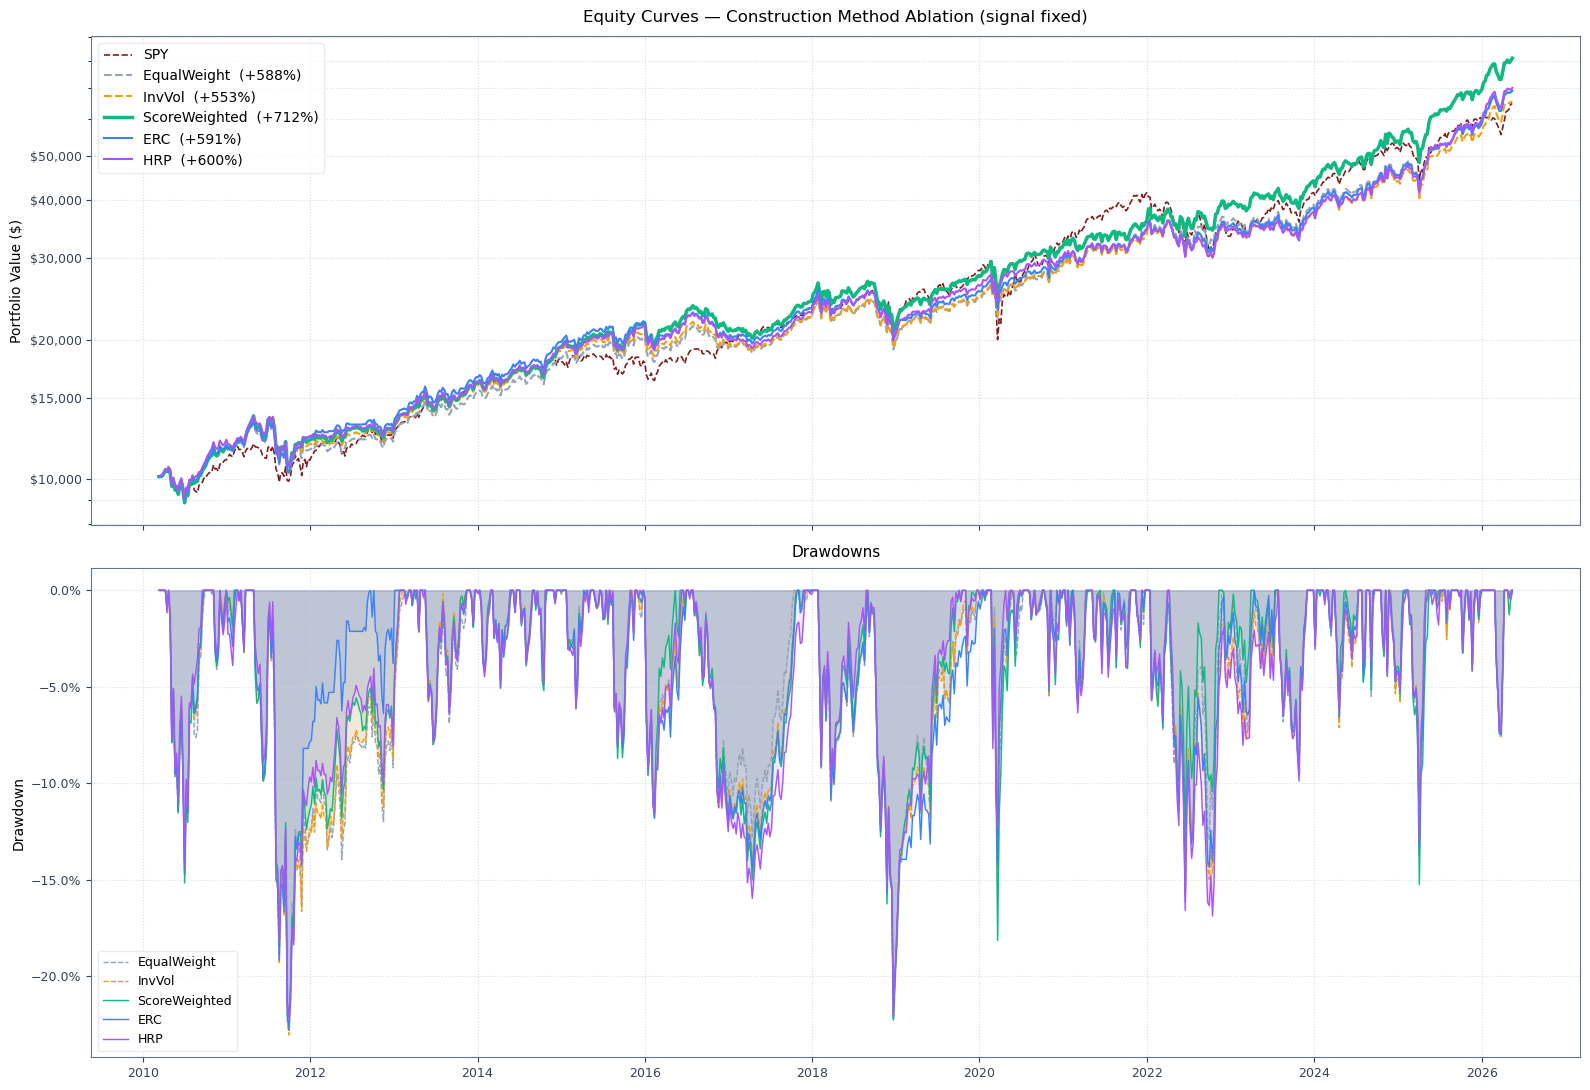


CONSTRUCTION METHOD ABLATION — Signal fixed (K2=5 ICIR-weighted, K1=3 ICIR-weighted)
                 CAGR     Vol Sharpe Sortino    MaxDD Calmar HitRate Alpha_ann
SPY            12.18%  16.23%  0.790   0.955  -32.23%   0.38   58.2%     0.00%
EqualWeight    12.60%  15.77%  0.833   1.067  -22.41%   0.56   59.2%     0.30%
InvVol         12.24%  15.27%  0.834   1.059  -23.03%   0.53   59.4%    -0.10%
ScoreWeighted  13.76%  15.58%  0.906   1.149  -22.26%   0.62   60.2%     1.29%
ERC            12.63%  15.17%  0.861   1.082  -22.79%   0.55   58.5%     0.23%
HRP            12.73%  15.04%  0.873   1.113  -22.16%   0.57   60.6%     0.30%

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶
  SECTION 1 WINNER: ScoreWeighted
  → Fixed for Section 2: sizing method = ScoreWeighted
  → Now varying: feature combination weights (ICIR / Equal / IC)
▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶



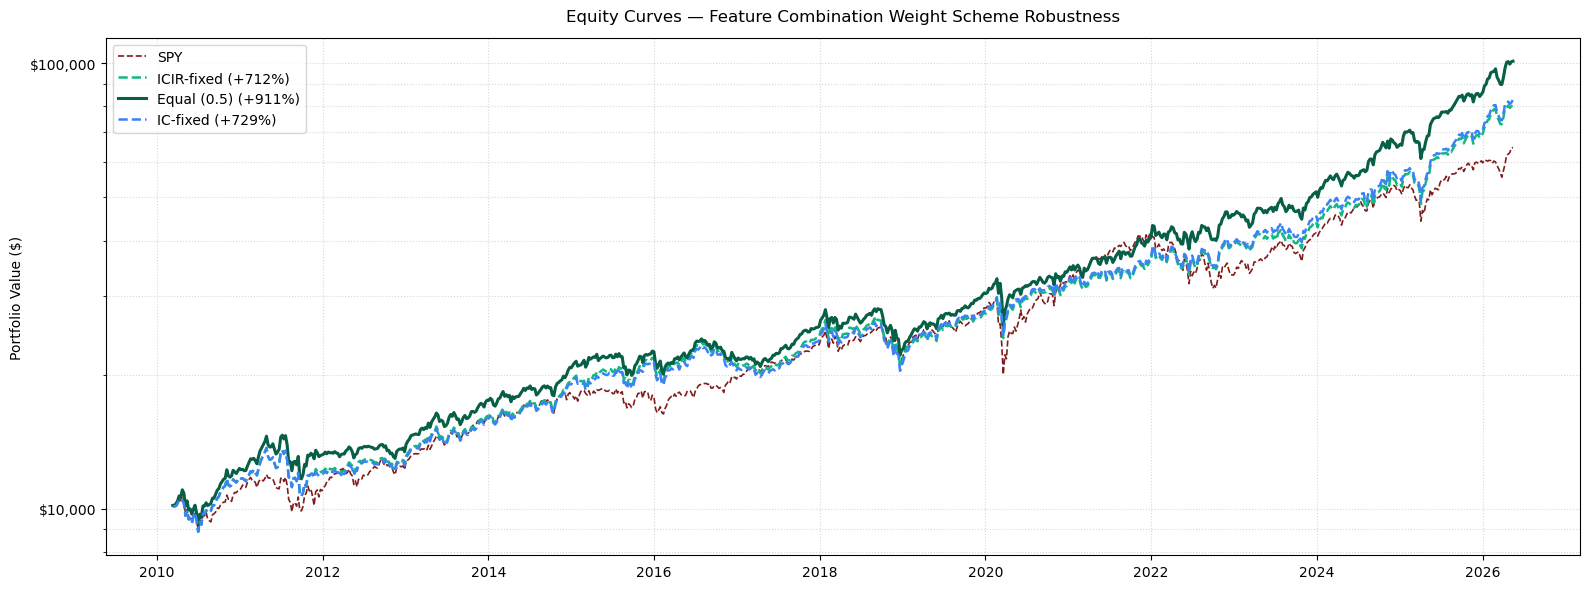


FEATURE COMBINATION ROBUSTNESS — ScoreWeighted sizing, scheme varies
  Scheme                 CAGR   Sharpe   Sortino    MaxDD
  --------------------------------------------------------
  ICIR-fixed           13.76%    0.906     1.149  -22.26%
  Equal (0.5)          15.30%    0.993     1.252  -21.58%
  IC-fixed             13.90%    0.916     1.159  -22.26%

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶
  SECTION 2 WINNER: Equal (0.5)
      Sizing method     : ScoreWeighted
      Feature weights   : Equal (0.5)
▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶


  Note: fixed ICIR weights are a reasonable approximation of the dynamic

✅ DOWNSTREAM BASELINE UPDATED SUCCESSFULLY
   Baseline Strategy : ScoreWeighted | Scheme: Equal (0.5)
   New Baseline Sharpe: 0.993  (CAGR: 15.30%)



In [10]:
# SECTION 1: Construction Method Ablation (signal fixed, weighting varies)

spy_r   = spy_close.pct_change().dropna()
method_rets_series = {name: pd.Series(rets).sort_index().dropna()
                      for name, rets in method_rets.items()}
common  = list(method_rets_series.values())[0].index.intersection(spy_r.index)

P = {"SPY": spy_r.reindex(common).fillna(0)}
for name, s in method_rets_series.items():
    P[name] = s.reindex(common).fillna(0)

PAL = {
    "EqualWeight"  : ("#94a3b8", 1.5, "--"),
    "InvVol"       : ("#f59e0b", 1.5, "--"),
    "ScoreWeighted": ("#10b981", 2.5, "-"),
    "ERC"          : ("#3b82f6", 1.5, "-"),
    "HRP"          : ("#a855f7", 1.5, "-"),
}

def equity(s, v=10_000): return (1 + s).cumprod() * v
def mdd_s(s):            c = (1 + s).cumprod(); return c / c.cummax() - 1


# ── Chart 1a: Equity + Drawdown — construction methods ───────────────────────
# reset the global plot style (cell 1 set a dark theme)
plt.style.use("default")

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(16, 11),
    sharex=True,
    facecolor="white"
)

ax1.set_facecolor("white")
ax2.set_facecolor("white")

# Benchmark SPY
ax1.plot(
    equity(P["SPY"]).index,
    equity(P["SPY"]).values,
    color="#7F1D1D", lw=1.2, ls="--", label="SPY"
)

# equity curves for each construction method
for name, (col, lw, ls) in PAL.items():
    s   = P[name]
    tot = (1 + s).prod() - 1
    ax1.plot(
        equity(s).index, equity(s).values,
        color=col, lw=lw, ls=ls,
        label=f"{name}  ({tot:+.0%})"
    )

# log-scale axis & grid for the equity panel
ax1.set_yscale("log")

ax1.yaxis.set_major_locator(mticker.LogLocator(base=10.0, subs=(1.0, 1.5, 2.0, 3.0, 4.0, 5.0)))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax1.yaxis.set_minor_formatter(mticker.NullFormatter())  # Nasconde tick secondari disallineati

ax1.set_title("Equity Curves — Construction Method Ablation (signal fixed)", fontsize=12, pad=10)
ax1.set_ylabel("Portfolio Value ($)", fontsize=10)
ax1.grid(True, which="both", color="#cbd5e1", linestyle=":", alpha=0.8)
ax1.legend(fontsize=10, loc="upper left", frameon=True, facecolor="white", edgecolor="#e2e8f0")

# Drawdowns ax2
for name, (col, lw, ls) in PAL.items():
    dd = mdd_s(P[name])
    ax2.fill_between(dd.index, dd.values, 0, alpha=0.12, color=col)
    ax2.plot(dd.index, dd.values, color=col, lw=1.0, ls=ls, label=name)

# drawdown axis formatting (ax2)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax2.set_title("Drawdowns", fontsize=11, pad=8)
ax2.set_ylabel("Drawdown", fontsize=10)
ax2.grid(True, which="both", color="#cbd5e1", linestyle=":", alpha=0.8)
ax2.legend(fontsize=9, loc="lower left", frameon=True, facecolor="white", edgecolor="#e2e8f0")

# visible borders on both axes
for ax in (ax1, ax2):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#64748b")
        spine.set_linewidth(0.8)
    ax.tick_params(colors="#334155", labelsize=9)

plt.tight_layout()
plt.savefig("figures/ablation_equity_drawdown.png.png", bbox_inches="tight", dpi=150)
plt.show()

# ── Performance table ─────────────────────────────────────────────────────────
print("\n" + "="*90)
print("CONSTRUCTION METHOD ABLATION — Signal fixed (K2=5 ICIR-weighted, K1=3 ICIR-weighted)")
print("="*90)
tbl = {"SPY": perf_row(P["SPY"], P["SPY"])}
for name in PAL:
    tbl[name] = perf_row(P[name], P["SPY"])
print(pd.DataFrame(tbl).T.to_string())


# ── Scheme robustness loop — ALL construction methods ─────────────────────────
scheme_method_rets = {s: {name: {} for name in CONSTRUCTION_METHODS}
                      for s in WEIGHT_SCHEMES}
scheme_hyst = {s: {} for s in WEIGHT_SCHEMES}
raw_scores_by_scheme = {s: {} for s in WEIGHT_SCHEMES}

for t in range(SEED_WEEKS, len(dates_full) - 1):
    dt      = dates_full[t]
    dt_prev = dates_full[t - 1]
    exp_scalar = soft_exposure(vix_pct.get(dt_prev, 0.5))

    for scheme, wts in WEIGHT_SCHEMES.items():
        wp = wts["L2"]["poc_cross"];  wm = wts["L2"]["mom_52w"]
        wk = wts["L1"]["kalman_dev"]; ws = wts["L1"]["sma_deriv_neg"]

        f_s = SelectionFunnel(feat_raw, kalman_z, sma_deriv_neg_z, dates_full, ASSETS,
                             w_poc=wp, w_mom=wm, w_kalman=wk, w_sma_neg=ws)
        scores_raw = f_s.get_selection(t)
        raw_scores_by_scheme[scheme][t] = dict(scores_raw)
        if len(scores_raw) < 2:
            continue

        # Hysteresis: same margin-based protection as main loop
        prev_tickers = scheme_hyst[scheme].get(dt_prev, [])
        scores = apply_hysteresis_margin(scores_raw, prev_tickers, K1, HYSTERESIS_MARGIN)

        if len(scores) < 2:
            continue

        tickers = list(scores.keys())
        scheme_hyst[scheme][dt] = tickers

        rets_t = np.array([
            prices_mat[t, ASSETS.index(tk)] / prices_mat[t-1, ASSETS.index(tk)] - 1
            for tk in tickers
        ])
        # all construction methods
        for name, fn in CONSTRUCTION_METHODS.items():
            try:
                w = fn(tickers, t, scores)
                scheme_method_rets[scheme][name][dt] = float(np.dot(w, rets_t)) * exp_scalar
            except Exception:
                scheme_method_rets[scheme][name][dt] = np.nan


# announce winner carried forward to Section 2
best_method = max([n for n in PAL],
                  key=lambda n: float(perf_row(P[n], P["SPY"])["Sharpe"]))
BEST_SIZING = best_method


print(f"\n{'▶'*70}")
print(f"  SECTION 1 WINNER: {BEST_SIZING}")
print(f"  → Fixed for Section 2: sizing method = {BEST_SIZING}")
print(f"  → Now varying: feature combination weights (ICIR / Equal / IC)")
print(f"{'▶'*70}\n")


scheme_series = {
    scheme: pd.Series(scheme_method_rets[scheme][BEST_SIZING]).sort_index().dropna()
    for scheme in WEIGHT_SCHEMES
}
c_s = list(scheme_series.values())[0].index

# SECTION 2: Feature Combination Robustness (ICIR-fixed vs Equal vs IC-fixed)

SCHEME_COLORS = {
    "ICIR-fixed": "#10b981",
    "Equal (0.5)": "#f59e0b",
    "IC-fixed"  : "#3b82f6",
}


# ── Chart 2: Equity Curves — Weight Schemes ───────────────────────────────────
plt.style.use("default")

# single panel (no drawdown subplot here)
fig, ax1 = plt.subplots(figsize=(16, 6))

# SPY benchmark (grey dotted line)
ax1.plot(
    equity(spy_r.reindex(c_s)).index,
    equity(spy_r.reindex(c_s)).values,
    color="#7F1D1D",
    lw=1.2,
    ls="--",
    label="SPY",
)

# iterate over all weight schemes
for scheme, s in scheme_series.items():
    s_a = s.reindex(c_s).fillna(0)
    tot = (1 + s_a).prod() - 1

    # detect the Equal-weight variant ("Equal (0.5)" or plain "EqualWeight")
    if "Equal" in scheme:
        color = "#065F46"  # Verde scuro (Dark Emerald)
        ls = "-"        # Linea continua (piena)
        lw = 2.2
    else:
        # color from SCHEME_COLORS with a blue fallback
        color = SCHEME_COLORS.get(scheme, "#3B82F6")
        ls = "--"       # Linea tratteggiata (dashed)
        lw = 1.8

    ax1.plot(
        equity(s_a).index,
        equity(s_a).values,
        color=color,
        lw=lw,
        ls=ls,
        label=f"{scheme} ({tot:+.0%})",
    )

# log scale & axis formatting
ax1.set_yscale("log")
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
ax1.set_title(
    "Equity Curves — Feature Combination Weight Scheme Robustness",
    fontsize=12,
    pad=12,
)
ax1.set_ylabel("Portfolio Value ($)")
ax1.legend(fontsize=10, loc="upper left")
ax1.grid(True, which="both", ls=":", alpha=0.5)

plt.tight_layout()
plt.savefig("figures/pnls.png.png", bbox_inches="tight", dpi=300)
plt.show()


# ── Table ─────────────────────────────────────────────────────────────────────
print("\n" + "="*75)
print("FEATURE COMBINATION ROBUSTNESS — ScoreWeighted sizing, scheme varies")
print("="*75)
print(f"  {'Scheme':<18} {'CAGR':>8} {'Sharpe':>8} {'Sortino':>9} {'MaxDD':>8}")
print("  " + "-"*56)
for scheme, s in scheme_series.items():
    s_a = s.reindex(c_s).fillna(0)
    m    = perf_stats(s_a, sortino_variant="negonly")
    cagr, sr, so, mdd = m["CAGR"], m["Sharpe"], m["Sortino"], m["MaxDD"]
    print(f"  {scheme:<18} {cagr:>8.2%} {sr:>8.3f} {so:>9.3f} {mdd:>8.2%}")


# ── Announce winner carried forward ──────────────────────────────────────────
best_scheme = max(scheme_series.keys(),
                  key=lambda s: scheme_series[s].mean() /
                                (scheme_series[s].std() + 1e-10))
print(f"\n{'▶'*70}")
print(f"  SECTION 2 WINNER: {best_scheme}")
print(f"      Sizing method     : {BEST_SIZING}")
print(f"      Feature weights   : {best_scheme}")
print(f"{'▶'*70}\n")

print("\n  Note: fixed ICIR weights are a reasonable approximation of the dynamic")


# BRIDGE: carry the Section-2 winner forward into downstream sections

# 1. overwrite P[winner method] with the winning scheme's series
P[BEST_SIZING] = pd.Series(scheme_method_rets[best_scheme][BEST_SIZING]) \
                   .sort_index().reindex(common).fillna(0)

# 2. refresh the selection log (used downstream by turnover/cost/DSR sections)
sel_log = scheme_hyst[best_scheme]
selection_log = scheme_hyst[best_scheme]   # kept under this name for downstream cells

# 3. immediate sanity check
s_win = P[BEST_SIZING]
_m    = perf_stats(s_win)
cagr_w, sr_w = _m["CAGR"], _m["Sharpe"]

print(f"\n{'='*75}")
print(f"✅ DOWNSTREAM BASELINE UPDATED SUCCESSFULLY")
print(f"   Baseline Strategy : {BEST_SIZING} | Scheme: {best_scheme}")
print(f"   New Baseline Sharpe: {sr_w:.3f}  (CAGR: {cagr_w:.2%})")
print(f"{'='*75}\n")


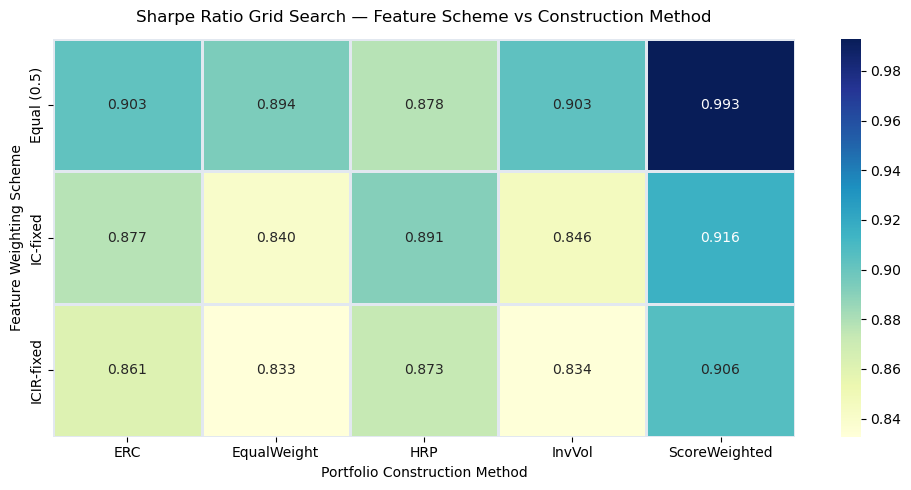


FULL COMBINATORIAL ABLATION — TOP COMBINATIONS (Scheme × Method)
     Scheme        Method   CAGR    Vol Sharpe   MaxDD
Equal (0.5) ScoreWeighted 15.30% 15.59%  0.993 -21.58%
   IC-fixed ScoreWeighted 13.90% 15.56%  0.916 -22.26%
 ICIR-fixed ScoreWeighted 13.76% 15.58%  0.906 -22.26%
Equal (0.5)        InvVol 13.58% 15.44%  0.903 -21.88%
Equal (0.5)           ERC 13.50% 15.36%  0.903 -22.33%
Equal (0.5)   EqualWeight 13.75% 15.85%  0.894 -21.50%
   IC-fixed           HRP 13.02% 15.03%  0.891 -22.16%
Equal (0.5)           HRP 13.11% 15.42%  0.878 -23.55%
   IC-fixed           ERC 12.88% 15.14%  0.877 -22.79%
 ICIR-fixed           HRP 12.73% 15.04%  0.873 -22.16%
 ICIR-fixed           ERC 12.63% 15.17%  0.861 -22.79%
   IC-fixed        InvVol 12.42% 15.23%  0.846 -23.03%
   IC-fixed   EqualWeight 12.68% 15.70%  0.840 -22.41%
 ICIR-fixed        InvVol 12.24% 15.27%  0.834 -23.03%
 ICIR-fixed   EqualWeight 12.60% 15.77%  0.833 -22.41%

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# GRID SEARCH EVALUATION: ALL SCHEMES × ALL CONSTRUCTION METHODS

grid_results = []

for scheme in WEIGHT_SCHEMES:
    for method in CONSTRUCTION_METHODS:
        s = pd.Series(scheme_method_rets[scheme][method]).sort_index().dropna()
        s_a = s.reindex(common).fillna(0)

        m = perf_stats(s_a, sortino_variant="negonly")

        grid_results.append({
            "Scheme": scheme,
            "Method": method,
            "CAGR": m["CAGR"],
            "Vol": m["AnnVol"],
            "Sharpe": m["Sharpe"],
            "MaxDD": m["MaxDD"],
            "Series": s_a
        })

df_grid = pd.DataFrame(grid_results)

# 1. Matrice Pivot per Sharpe Ratio
sharpe_matrix = df_grid.pivot(index="Scheme", columns="Method", values="Sharpe")
cagr_matrix = df_grid.pivot(index="Scheme", columns="Method", values="CAGR")

# heatmap of the full grid
plt.figure(figsize=(10, 5), facecolor="white")
sns.heatmap(
    sharpe_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    cbar=True,
    linewidths=1,
    linecolor="#e2e8f0"
)
plt.title("Sharpe Ratio Grid Search — Feature Scheme vs Construction Method", fontsize=12, pad=12)
plt.xlabel("Portfolio Construction Method", fontsize=10)
plt.ylabel("Feature Weighting Scheme", fontsize=10)
plt.tight_layout()
plt.savefig("figures/grid_search_sharpe_heatmap.png.png", dpi=300)
plt.show()

# ── Print full table ordered by Sharpe ───────────────────────────────
print("\n" + "="*85)
print("FULL COMBINATORIAL ABLATION — TOP COMBINATIONS (Scheme × Method)")
print("="*85)
df_sorted = df_grid.sort_values(by="Sharpe", ascending=False)
print(df_sorted[["Scheme", "Method", "CAGR", "Vol", "Sharpe", "MaxDD"]].to_string(
    index=False,
    formatters={
        "CAGR": "{:.2%}".format,
        "Vol": "{:.2%}".format,
        "Sharpe": "{:.3f}".format,
        "MaxDD": "{:.2%}".format
    }
))

# ── Print best combination───────────────────────────────
best_combination = df_sorted.iloc[0]
BEST_SCHEME = best_combination["Scheme"]
BEST_SIZING = best_combination["Method"]

print(f"\n{'▶'*70}")
print(f"  GLOBAL WINNER (JOINT OPTIMUM):")
print(f"    • Feature Weighting Scheme : {BEST_SCHEME}")
print(f"    • Portfolio Sizing Method : {BEST_SIZING}")
print(f"    • Global Sharpe           : {best_combination['Sharpe']:.3f}")
print(f"    • Global CAGR             : {best_combination['CAGR']:.2%}")
print(f"{'▶'*70}\n")

# DOWNSTREAM UPDATE WITH GLOBAL WINNER

# 1. Update dictionary P with the absolute winning combination
P[BEST_SIZING] = best_combination["Series"]

# 2. Aggiorna il registro delle selezioni storiche (Turnover, Costi e DSR)
sel_log = scheme_hyst[BEST_SCHEME]
selection_log = scheme_hyst[BEST_SCHEME]

print(f"✅ DOWNSTREAM BASELINE UPDATED WITH GLOBAL WINNER ({BEST_SCHEME} + {BEST_SIZING})")

## Diagnostics — concentration & rolling Sharpe of the winning scheme

Checks weight concentration over the last five rebalances and the rolling-52w
Sharpe path of `WINNING_SCHEME` + `BEST_SIZING`, using the logs from the main
loop.


In [12]:
# ── Concentration check (weights at last 5 rebalances, all construction methods) ──
# spy_r, common, P, PAL, equity, mdd_s are already defined in
# the Section 1 cell above (construction-method ablation) -- reused here as-is.
print("\n── CONCENTRATION CHECK (sample weights at last 5 rebalances) ──────────")
sample_dates = list(selection_log.keys())[-5:]
for dt in sample_dates:
    tickers = selection_log[dt]
    t_idx = list(dates_full).index(dt)
    scores = funnel.get_selection(t_idx)
    print(f"\n  {dt.date()}  selected={tickers}")
    for name, fn in CONSTRUCTION_METHODS.items():
        w = fn(tickers, t_idx, scores)
        hhi = (w**2).sum()
        eff_n = 1.0 / hhi
        print(f"    {name:<14}  weights={np.round(w,3)}  eff_n={eff_n:.2f}")



── CONCENTRATION CHECK (sample weights at last 5 rebalances) ──────────

  2026-04-17  selected=['EEM', 'GLD', 'EWJ']
    EqualWeight     weights=[0.333 0.333 0.333]  eff_n=3.00
    InvVol          weights=[0.368 0.287 0.345]  eff_n=2.97
    ScoreWeighted   weights=[0.266 0.488 0.246]  eff_n=2.71
    ERC             weights=[0.36  0.309 0.332]  eff_n=2.99
    HRP             weights=[0.355 0.35  0.296]  eff_n=2.98

  2026-04-24  selected=['EEM', 'GLD', 'XLE']
    EqualWeight     weights=[0.333 0.333 0.333]  eff_n=3.00
    InvVol          weights=[0.323 0.311 0.366]  eff_n=2.99
    ScoreWeighted   weights=[0.074 0.303 0.623]  eff_n=2.06
    ERC             weights=[0.32  0.248 0.432]  eff_n=2.85
    HRP             weights=[0.32  0.193 0.487]  eff_n=2.65

  2026-05-01  selected=['EEM', 'GLD', 'XLI']
    EqualWeight     weights=[0.333 0.333 0.333]  eff_n=3.00
    InvVol          weights=[0.299 0.289 0.412]  eff_n=2.92
    ScoreWeighted   weights=[0.106 0.608 0.287]  eff_n=2.16
    ERC  

## Portfolio Composition Analysis — selection frequency per ticker

How often each asset is held across the OOS window, and how concentrated the
chosen sleeve is relative to an equal-weight baseline.


TICKER SELECTION FREQUENCY — Full OOS Period
Total rebalance periods: 845
  Ticker      Times Selected  Selection Rate  Category
  ----------------------------------------------------------
  XLK                    318          37.6%  Sector
  XLY                    266          31.5%  Sector
  GLD                    211          25.0%  Real Asset
  XLF                    196          23.2%  Sector
  XLV                    185          21.9%  Sector
  XLI                    178          21.1%  Sector
  IWM                    149          17.6%  Equity Index
  XLU                    136          16.1%  Sector
  XLP                    127          15.0%  Sector
  VNQ                    121          14.3%  Real Asset
  XLE                    116          13.7%  Sector
  TLT                    103          12.2%  Bond
  DIA                     97          11.5%  Equity Index
  EWJ                     91          10.8%  Equity Index
  EFA                     87          10.3%  Equity Index


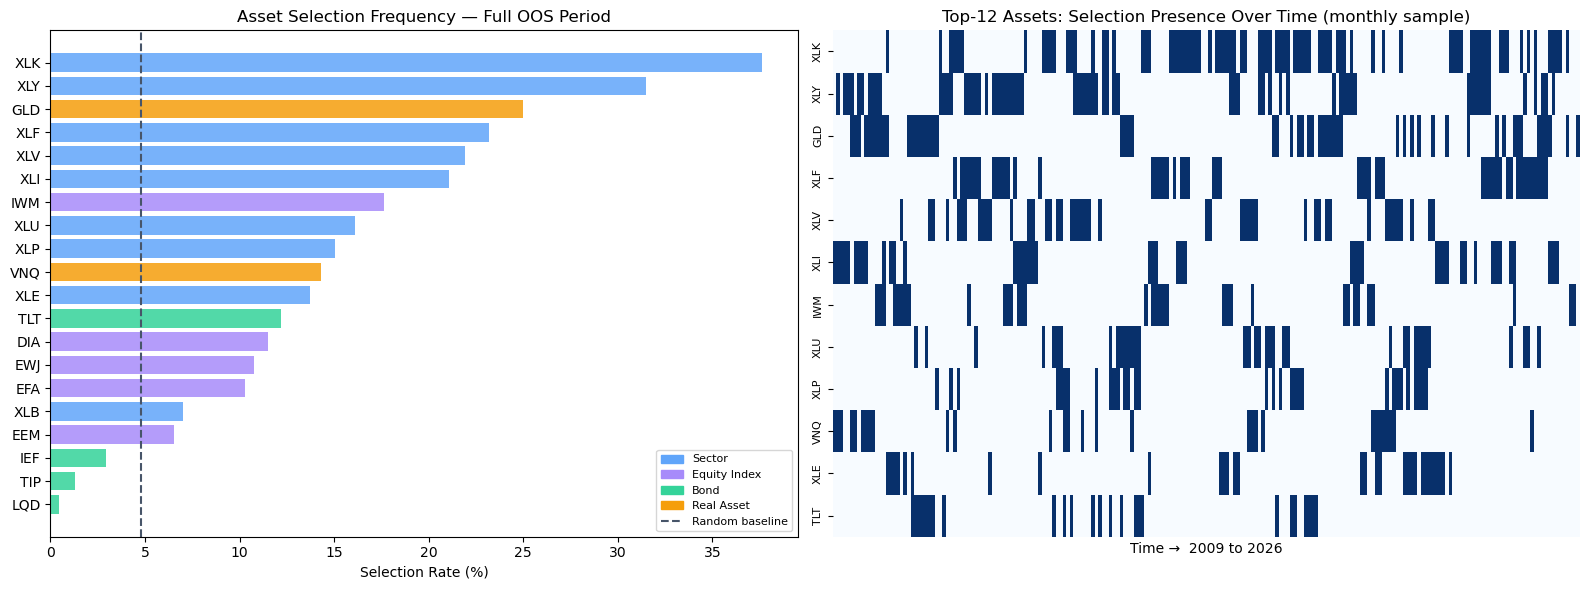


PORTFOLIO TURNOVER
  Mean weekly turnover  : 22.7% of portfolio replaced per week
  Median weekly turnover: 33.3%
  Weeks with no change  : 288 (34.1%)
  Implied annual turnover: 1181% of portfolio per year


In [13]:
# ── Ticker Selection Frequency ────────────────────────────────────────────────
from collections import Counter
import matplotlib.patches as mpatches

# Flatten all selected tickers across the full OOS period
all_selected = [tkr for tickers in selection_log.values() for tkr in tickers]
total_periods = len(selection_log)
freq = Counter(all_selected)

# Build a clean DataFrame sorted by frequency
df_freq = pd.DataFrame([
    {"Ticker": tkr,
     "Times Selected": cnt,
     "Selection Rate": cnt / total_periods,
     "Avg Periods Held": cnt / total_periods * 100}
    for tkr, cnt in sorted(freq.items(), key=lambda x: -x[1])
])

print("TICKER SELECTION FREQUENCY — Full OOS Period")
print(f"Total rebalance periods: {total_periods}")
print("="*65)
print(f"  {'Ticker':<10} {'Times Selected':>15} {'Selection Rate':>15}  Category")
print("  " + "-"*58)

# Asset category labels for readability
CATEGORIES = {
    "XLK":"Sector","XLY":"Sector","XLF":"Sector","XLI":"Sector","XLB":"Sector",
    "XLE":"Sector","XLP":"Sector","XLU":"Sector","XLV":"Sector",
    "IWM":"Equity Index","EEM":"Equity Index","EFA":"Equity Index",
    "EWJ":"Equity Index","DIA":"Equity Index",
    "TLT":"Bond","IEF":"Bond","LQD":"Bond","HYG":"Bond","TIP":"Bond",
    "GLD":"Real Asset","VNQ":"Real Asset",
}
CAT_COLORS = {
    "Sector":"#60a5fa", "Equity Index":"#a78bfa",
    "Bond":"#34d399", "Real Asset":"#f59e0b",
}

for _, row in df_freq.iterrows():
    cat = CATEGORIES.get(row["Ticker"], "Other")
    print(f"  {row['Ticker']:<10} {row['Times Selected']:>15.0f} "
          f"{row['Selection Rate']:>14.1%}  {cat}")

# ── Bar chart ─────────────────────────────────────────────────────────────────
plt.style.use("default")  # Ensures a clear default theme

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor="white")

ax = axes[0]
ax.set_facecolor("white")  # Sets the first plot's background to white

tickers_sorted = df_freq["Ticker"].tolist()
rates = df_freq["Selection Rate"].tolist()
bar_colors = [CAT_COLORS.get(CATEGORIES.get(t, "Other"), "#94a3b8") for t in tickers_sorted]

bars = ax.barh(tickers_sorted[::-1], [r*100 for r in rates[::-1]],
               color=bar_colors[::-1], alpha=0.85)

ax.axvline(100/len(ASSETS), color="#475569", lw=1.5, ls="--",
           label=f"Random baseline ({100/len(ASSETS):.1f}%)")

ax.set_xlabel("Selection Rate (%)")
ax.set_title("Asset Selection Frequency — Full OOS Period")

legend_patches = [mpatches.Patch(color=c, label=cat)
                  for cat, c in CAT_COLORS.items()]
legend_patches.append(plt.Line2D([0], [0], color="#475569", ls="--", label="Random baseline"))
ax.legend(handles=legend_patches, fontsize=8, loc="lower right")

# ── Monthly heatmap ───────────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor("white")  # Sets the second plot's background to white

dates_sel = sorted(selection_log.keys())
monthly_dates = pd.date_range(dates_sel[0], dates_sel[-1], freq="4W")

presence = {}
for tkr in tickers_sorted[:12]:   # top 12 per frequenza
    row_vals = []
    for md in monthly_dates:
        nearest = min(dates_sel, key=lambda d: abs(d - md))
        row_vals.append(1 if tkr in selection_log.get(nearest, []) else 0)
    presence[tkr] = row_vals

df_presence = pd.DataFrame(presence, index=monthly_dates).T

sns.heatmap(df_presence, ax=ax2, cmap="Blues", cbar=False,
            xticklabels=False, yticklabels=True)

ax2.set_title("Top-12 Assets: Selection Presence Over Time (monthly sample)")
ax2.set_xlabel("Time →  2009 to 2026")
ax2.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig("figures/ticker_frequency.png.png", bbox_inches="tight", dpi=300, facecolor="white")
plt.show()
# ── Rotation quality: how often does the portfolio change? ────────────────────
dates_all = sorted(selection_log.keys())
turnover = []
for i in range(1, len(dates_all)):
    prev = set(selection_log[dates_all[i-1]])
    curr = set(selection_log[dates_all[i]])
    added = len(curr - prev)
    removed = len(prev - curr)
    turnover.append((added + removed) / 2 / len(curr))

print(f"\nPORTFOLIO TURNOVER")
print(f"  Mean weekly turnover  : {np.mean(turnover):.1%} of portfolio replaced per week")
print(f"  Median weekly turnover: {np.median(turnover):.1%}")
print(f"  Weeks with no change  : {sum(1 for t in turnover if t==0)} "
      f"({sum(1 for t in turnover if t==0)/len(turnover):.1%})")
print(f"  Implied annual turnover: {np.mean(turnover)*52*100:.0f}% of portfolio per year")


## Robustness & Significance — regimes, turnover, JKM/DSR

Regime-conditional performance (VIX terciles), annualised turnover of the
winning scheme, net Sharpe under transaction costs, and formal significance
tests (Jobson-Korkie-Memmel + deflated Sharpe ratio) on the OOS series.


In [14]:
# ── 0. SETUP DYNAMIC KEYS & FALLBACKS ─────────────────────────────────────────
import scipy.stats as scipy_stats
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

# Define our primary winning scheme key
WINNING_SCHEME = "Equal (0.5)"
WINNING_METHOD = "ScoreWeighted"

P = {"SPY": spy_r.reindex(common).fillna(0)}
for name, rets_d in scheme_method_rets[WINNING_SCHEME].items():
    P[name] = pd.Series(rets_d).sort_index().reindex(common).fillna(0)

sel_log = scheme_hyst[WINNING_SCHEME]
SHOW = [k for k in ["SPY", "EqualWeight", "InvVol", "ScoreWeighted", "ERC", "HRP"] if k in P]


# ── LOCAL HELPERS  ────────────────────────────────────────────────────────────
def perf_sub(s, mask):
    idx = mask[mask].index.intersection(s.index)
    sub = s.reindex(idx).dropna()
    if len(sub) < 20:
        return {"Sharpe": np.nan, "CAGR": np.nan, "MaxDD": np.nan, "Hit%": np.nan}
    m = perf_stats(sub)
    return {"Sharpe": m["Sharpe"], "CAGR": m["CAGR"],
            "MaxDD": m["MaxDD"], "Hit%": m["HitRate"]}

# ── 1. REGIME-CONDITIONAL PERFORMANCE ────────────────────────────────────────
vix_pct_oos = vix_pct.reindex(common)
q1 = vix_pct_oos.quantile(1/3)
q2 = vix_pct_oos.quantile(2/3)

vix_regimes = {
    "Low VIX (calm)":    vix_pct_oos <= q1,
    "Mid VIX":            (vix_pct_oos > q1) & (vix_pct_oos <= q2),
    "High VIX (stress)": vix_pct_oos > q2,
}
era_split = pd.Timestamp("2022-01-01")
era_regimes = {
    "2009-2021 (low-rate)": pd.Series(common < era_split, index=common),
    "2022-2026 (hiking)":   pd.Series(common >= era_split, index=common),
}

for title, regime_dict in [("VIX TERCILES", vix_regimes),
                            ("PRE / POST 2022", era_regimes)]:
    print(f"\nREGIME-CONDITIONAL PERFORMANCE — {title}")
    print("=" * 80)
    for regime, mask in regime_dict.items():
        print(f"\n  {regime}  (n={mask.sum()} weeks)")
        print(f"  {'Method':<18} {'Sharpe':>8} {'CAGR':>8} {'MaxDD':>8} {'Hit%':>7}")
        print("  " + "-" * 48)
        for name in SHOW:
            r = perf_sub(P[name], mask)
            sh   = f"{r['Sharpe']:8.3f}" if not np.isnan(r['Sharpe']) else "     nan"
            cagr = f"{r['CAGR']:8.2%}"   if not np.isnan(r['CAGR'])  else "     nan"
            mdd  = f"{r['MaxDD']:8.2%}"  if not np.isnan(r['MaxDD']) else "     nan"
            hit  = f"{r['Hit%']:7.1%}"   if not np.isnan(r['Hit%'])  else "    nan"
            print(f"  {name:<18} {sh} {cagr} {mdd} {hit}")


# ── 2. TURNOVER + NET-OF-COSTS + BREAK-EVEN ──────────────────────────────────
dates_sorted = sorted(sel_log.keys())
weekly_to = []
for i in range(1, len(dates_sorted)):
    prev = set(sel_log.get(dates_sorted[i-1], []))
    curr = set(sel_log.get(dates_sorted[i], []))
    if dates_sorted[i] not in common: continue
    weekly_to.append(len(curr - prev) / max(len(curr), 1))
annual_to = np.mean(weekly_to) * 52 if weekly_to else 0

spy_sh = sharpe_ann(P["SPY"]) if "SPY" in P else np.nan

print("\n" + "=" * 90)
print("TURNOVER & NET-OF-COSTS ANALYSIS")
print(f"  Annualised one-way turnover: {annual_to:.0%}/year  ({np.mean(weekly_to):.1%}/week mean)")
print("=" * 90)
print(f"  {'Method':<18} {'Gross':>7} {'@2bp':>7} {'@5bp':>7} {'@10bp':>8} {'Break-even':>12}")
print("  " + "-" * 68)
for name in [k for k in SHOW if k != "SPY"]:
    s = P[name]
    g   = sharpe_ann(s)
    n2  = net_sharpe(s, annual_to, 0.0002)
    n5  = net_sharpe(s, annual_to, 0.0005)
    n10 = net_sharpe(s, annual_to, 0.0010)

    s_clean = s.reindex(common).dropna()
    cagr_s  = (1 + s_clean).prod()**(52 / len(s_clean)) - 1
    vol_s   = s_clean.std() * np.sqrt(52)
    be      = (cagr_s - spy_sh * vol_s) / (annual_to + 1e-10) if not np.isnan(spy_sh) else np.nan
    be_str  = f"{be*10000:>10.1f}bp" if not np.isnan(be) else "       nan"
    print(f"  {name:<18} {g:>7.3f} {n2:>7.3f} {n5:>7.3f} {n10:>8.3f} {be_str}")


# ── 3. DEFLATED SHARPE RATIO ─────────────────────────────────────────────────
N_TRIALS = 15  # 5 sizing methods x 3 feature schemes
print(f"\nDEFLATED SHARPE RATIO (Lopez de Prado 2014) — N_trials={N_TRIALS}")
print("=" * 70)
print(f"  {'Method':<18} {'Sharpe':>8} {'DSR':>8}  Verdict")
print("  " + "-" * 46)
for name in [k for k in SHOW if k != "SPY"]:
    s   = P[name].dropna()
    sh  = sharpe_ann(s)
    dsr = deflated_sr(sh, len(s), N_TRIALS)
    v   = "SIGNIFICANT" if dsr > 0.95 else "MARGINAL" if dsr > 0.90 else "not significant"
    print(f"  {name:<18} {sh:>8.3f} {dsr:>8.4f}  {v}")


# ── 4. JOBSON-KORKIE-MEMMEL TEST ─────────────────────────────────────────────
# --- TABLE1: Baseline (ScoreWeighted) vs Alternatives ---
sw_key = "ScoreWeighted"

if sw_key in P:
    sw_baseline = P[sw_key]
    print(f"JOBSON-KORKIE-MEMMEL TEST — Baseline ({sw_key}) vs Alternatives")
    print("  H0: SR(Baseline) = SR(alt). Reject H0 if p < 0.05")
    print("=" * 65)
    print(f"  {'vs Method':<20} {'z-stat':>9} {'p-value':>9}  Verdict")
    print("  " + "-" * 50)

    for name in SHOW:
        if name == sw_key or name not in P:
            continue

        # Chiamata al test
        z, p = jobson_korkie_memmel(sw_baseline, P[name])

        v  = "SIGNIFICANT" if (not np.isnan(p) and p < 0.05) else "not significant"
        zs = f"{z:9.3f}" if not np.isnan(z) else "      nan"
        ps = f"{p:9.4f}" if not np.isnan(p) else "      nan"
        print(f"  {name:<20} {zs} {ps}  {v}")

# --- TABLE2: Feature Weighting Schemes ---
if 'scheme_series' in globals() and len(scheme_series) > 1:
    print("\n  --- Feature Weighting Schemes JKM Comparison ---")
    sch_names = list(scheme_series.keys())
    base_sch = sch_names[0]

    for alt_sch in sch_names[1:]:
        z_s, p_s = jobson_korkie_memmel(scheme_series[base_sch], scheme_series[alt_sch])

        v_s = "SIGNIFICANT" if (not np.isnan(p_s) and p_s < 0.05) else "not significant"
        zs = f"{z_s:9.3f}" if not np.isnan(z_s) else "      nan"
        ps = f"{p_s:9.4f}" if not np.isnan(p_s) else "      nan"
        print(f"  {base_sch} vs {alt_sch:<15} {zs} {ps}  {v_s}")

# ── 5. HRP DENOISED vs RAW (Marchenko-Pastur) ────────────────────────────────
print("\nHRP DENOISED vs HRP RAW (Lopez de Prado — Marchenko-Pastur)")


hrp_dn_rets = {}
for t in range(SEED_WEEKS, len(dates_full) - 1):
    dt = dates_full[t]
    if dt not in sel_log: continue
    tickers = sel_log[dt]
    if len(tickers) < 2: continue

    cov_raw = cm.cov_matrix(tickers, t)
    try:
        q_ratio = max(VOL_LOOKBACK, len(tickers) + 1) / len(tickers)
        cov_d   = _mp_denoise(cov_raw, q=q_ratio)
    except Exception:
        cov_d = cov_raw

    std_d  = np.sqrt(np.diag(cov_d))
    std_d  = np.where(std_d < 1e-10, 1e-10, std_d)
    corr_d = np.clip(cov_d / np.outer(std_d, std_d), -1, 1)
    np.fill_diagonal(corr_d, 1.0)
    dist_d = np.sqrt(np.clip((1 - corr_d) / 2, 0, 1))
    np.fill_diagonal(dist_d, 0.0)
    cond   = squareform(dist_d, checks=False)
    link   = linkage(cond, method="single")
    s_ix   = cm._hrp_quasi_diag(link)
    w      = cm._hrp_recursive_bisect(cov_d, s_ix)
    w      = w / (w.sum() + 1e-10)

    rets_t = np.array([prices_mat[t, ASSETS.index(tk)] / prices_mat[t-1, ASSETS.index(tk)] - 1 for tk in tickers])
    exp_sc = soft_exposure(vix_pct.get(dates_full[t-1], 0.5)) if 'soft_exposure' in globals() else 1.0
    hrp_dn_rets[dt] = float(np.dot(w, rets_t)) * exp_sc

hrp_dn = pd.Series(hrp_dn_rets).sort_index().reindex(common).fillna(0)
print("=" * 65)

if "HRP" in P:
    for label, s in [("HRP raw covariance", P["HRP"]), ("HRP MP-denoised", hrp_dn)]:
        sh   = sharpe_ann(s)
        s_c  = s.dropna()
        cagr = (1 + s_c).prod()**(52 / len(s_c)) - 1
        mdd  = mdd_s(s_c).min() if 'mdd_s' in globals() else ((1 + s_c).cumprod() / (1 + s_c).cumprod().cummax() - 1).min()
        print(f"  {label:<25} Sharpe={sh:.3f}  CAGR={cagr:.2%}  MaxDD={mdd:.2%}")

    # jobson_korkie_memmel 
    z_dn, p_dn = jobson_korkie_memmel(hrp_dn, P["HRP"])
    zs = f"{z_dn:.3f}" if not np.isnan(z_dn) else "nan"
    ps = f"{p_dn:.4f}" if not np.isnan(p_dn) else "nan"
    print(f"  JKM (denoised vs raw): z={zs}  p={ps}")
    P["HRP (denoised)"] = hrp_dn



REGIME-CONDITIONAL PERFORMANCE — VIX TERCILES

  Low VIX (calm)  (n=283 weeks)
  Method               Sharpe     CAGR    MaxDD    Hit%
  ------------------------------------------------
  SPY                   4.951   49.75%   -3.73%   75.3%
  EqualWeight           3.680   45.54%   -4.25%   70.7%
  InvVol                3.800   46.28%   -3.75%   70.7%
  ScoreWeighted         3.666   45.71%   -4.33%   71.0%
  ERC                   3.630   44.06%   -3.93%   68.6%
  HRP                   3.543   43.91%   -4.41%   70.0%

  Mid VIX  (n=281 weeks)
  Method               Sharpe     CAGR    MaxDD    Hit%
  ------------------------------------------------
  SPY                   1.885   23.87%  -26.35%   60.5%
  EqualWeight           1.577   21.15%  -22.94%   62.3%
  InvVol                1.549   20.05%  -24.44%   62.3%
  ScoreWeighted         1.758   23.74%  -22.82%   62.6%
  ERC                   1.596   20.62%  -24.75%   60.1%
  HRP                   1.588   20.52%  -24.41%   61.9%

  High 

## Hysteresis Ablation — turnover vs rebalancing drag

Re-runs the winning scheme's funnel with a score-margin threshold `delta` for
every candidate in `HYST_THRESHOLDS`. For each run it measures weekly one-way
turnover and two-way weight drift, then net Sharpe under 5bp costs — the
trade-off between turnover reduction and signal lag.


In [15]:
# HYSTERESIS ABLATION — Rigorous Turnover & Drag Breakdown
HYST_THRESHOLDS = [0.00, 0.02, 0.05, 0.10, 0.25, 0.50, 1.00, 2.00, 5.00]

WINNING_METHOD = "ScoreWeighted"

if 'P' in globals() and WINNING_METHOD in P:
    s_target = P[WINNING_METHOD]
elif 'scheme_method_rets' in globals() and WINNING_SCHEME in scheme_method_rets:
    s_target = pd.Series(scheme_method_rets[WINNING_SCHEME][WINNING_METHOD]).sort_index().reindex(common).fillna(0)
else:
    s_target = None

if s_target is not None:
    print(f"Target Ground Truth Sharpe ({WINNING_SCHEME} - {WINNING_METHOD}): {sharpe_ann(s_target):.3f}")



FEE_5BP = 0.0005

print("\nHYSTERESIS ABLATION ANALYSIS")
print("=" * 95)
print(f"  {'δ':>4} | {'Gross Sh':>8} | {'CAGR':>7} | {'MaxDD':>7} | "
      f"{'TO/wk':>6} | {'Reb.Drag':>9} | {'Net @5bp':>9} | {'Net Sh':>9}")
print("  " + "-" * 91)



s_h, wk_to, wk_reb = run_funnel_with_hysteresis(raw_scores_by_scheme[WINNING_SCHEME], 0.0,
                                                       cm, vix_pct, dates_full, common, K1)
print(f"wk_reb = {wk_reb:.6f}  ({wk_reb:.2%})")
print(f"reb_drag_bps = {wk_reb * FEE_5BP * 52 * 10_000:.1f}")

hyst_results = {}
for delta in HYST_THRESHOLDS:
    s_h, wk_to, wk_reb = run_funnel_with_hysteresis(raw_scores_by_scheme[WINNING_SCHEME], delta,
                                                       cm, vix_pct, dates_full, common, K1)

    s_clean = s_h.dropna()
    g_sh    = sharpe_ann(s_h)
    _m      = perf_stats(s_clean)
    cagr, mdd = _m["CAGR"], _m["MaxDD"]

    cost_sub_wk = wk_to  * 2 * FEE_5BP   # substistution
    cost_reb_wk = wk_reb * FEE_5BP        # drift 
    cost_tot_wk = cost_sub_wk + cost_reb_wk

    reb_drag_bps = max(0.0, cost_reb_wk * 52 * 10_000)
    net5         = sharpe_ann(s_h - cost_sub_wk)
    net_final    = sharpe_ann(s_h - cost_tot_wk)

    hyst_results[delta] = {
        "series"      : s_h,
        "wk_to"       : wk_to,
        "wk_reb"      : wk_reb,
        "gross_sh"    : g_sh,
        "cagr"        : cagr,
        "mdd"         : mdd,
        "reb_drag_bps": reb_drag_bps,
        "net5"        : net5,
        "net_final"   : net_final,
    }

    print(f"  {delta:>4.2f} | {g_sh:>8.3f} | {cagr:>7.2%} | {mdd:>7.2%} | "
          f"{wk_to:>6.1%} | {reb_drag_bps:>7.1f}bps | {net5:>9.3f} | {net_final:>9.3f}")

print("=" * 95)
print("Note:")
print("  • TO/wk    : Average fraction of assets replaced per week (one-way).")
print("  • Reb.Drag : Annual cost in bps of weight drift only (two-way), at 5bps.")
print("  • Net @5bp : Net Sharpe with only replacement commissions (5bps two-way).")
print("  • Net Sh   : Net Sharpe = 5bps replacement + rebalancing drift.")


Target Ground Truth Sharpe (Equal (0.5) - ScoreWeighted): 0.993

HYSTERESIS ABLATION ANALYSIS
     δ | Gross Sh |    CAGR |   MaxDD |  TO/wk |  Reb.Drag |  Net @5bp |    Net Sh
  -------------------------------------------------------------------------------------------
wk_reb = 0.048630  (4.86%)
reb_drag_bps = 12.6
  0.00 |    0.933 |  14.23% | -22.04% |  27.3% |    12.6bps |     0.842 |     0.834
  0.02 |    0.976 |  15.02% | -22.04% |  24.1% |    11.9bps |     0.895 |     0.888
  0.05 |    0.986 |  15.18% | -21.58% |  23.9% |    12.3bps |     0.907 |     0.899
  0.10 |    0.993 |  15.30% | -21.58% |  22.7% |    13.9bps |     0.917 |     0.908
  0.25 |    0.970 |  14.90% | -21.76% |  19.2% |    18.3bps |     0.906 |     0.894
  0.50 |    0.960 |  14.64% | -21.76% |  16.2% |    22.8bps |     0.905 |     0.891
  1.00 |    0.888 |  13.37% | -22.68% |  13.4% |    27.1bps |     0.843 |     0.825
  2.00 |    0.812 |  12.34% | -22.17% |  10.5% |    31.2bps |     0.778 |     0.758
  5.00 |  

## Probability of Backtest Overfitting (PBO) — Bailey, Borwein, López de Prado & Zhu (2017)

Combinatorially symmetric cross-validation (`helpers.cscv_pbo`) over the five
construction methods: how often the IS-winner stays top-ranked OOS. The logit
distribution and PBO value quantify selection risk of Section 1's winner.


PROBABILITY OF BACKTEST OVERFITTING (PBO) — 5 construction methods
  Strategies compared : ['EqualWeight', 'InvVol', 'ScoreWeighted', 'ERC', 'HRP']
  CSCV combinations   : 252  (S=10, C(10,5)=252)
  PBO                 : 4.8%
  Verdict             : LOW overfitting risk -- selection appears robust.


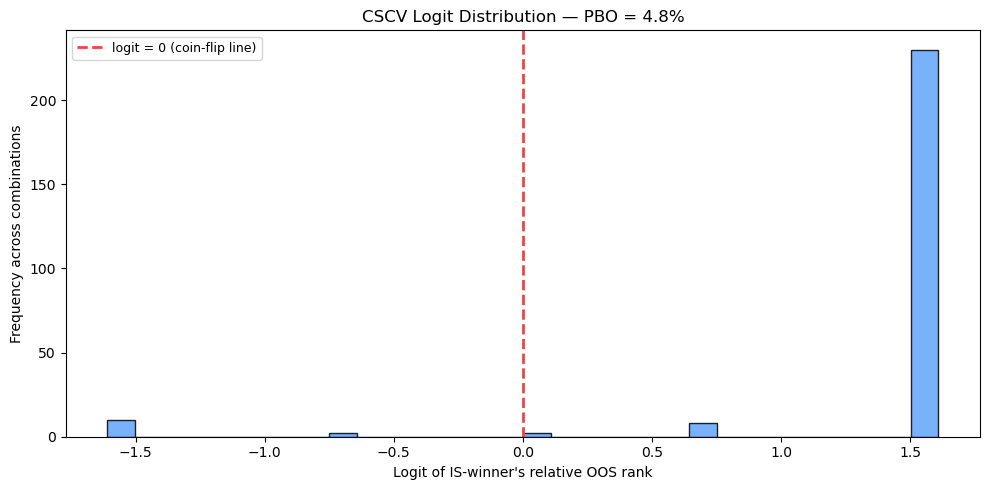

In [16]:
# 6. PROBABILITY OF BACKTEST OVERFITTING (PBO) — CSCV
#    Bailey, Borwein, Lopez de Prado & Zhu (2017), J. Computational Finance


# ── Run CSCV across the 5 construction methods (Section 1's comparison) ─────
pbo_input = {name: P[name] for name in CONSTRUCTION_METHODS if name in P}

try:
    pbo, logits, pbo_names = cscv_pbo(pbo_input, S=10)

    print("PROBABILITY OF BACKTEST OVERFITTING (PBO) — 5 construction methods")
    print("=" * 70)
    print(f"  Strategies compared : {pbo_names}")
    print(f"  CSCV combinations   : {len(logits)}  (S=10, C(10,5)=252)")
    print(f"  PBO                 : {pbo:.1%}")
    if pbo < 0.20:
        verdict = "LOW overfitting risk -- selection appears robust."
    elif pbo < 0.40:
        verdict = "MODERATE overfitting risk -- report PBO alongside DSR."
    else:
        verdict = ("HIGH overfitting risk -- the 'best' construction method "
                    "is not reliably distinguishable from the others OOS.")
    print(f"  Verdict             : {verdict}")

    # ── Logit distribution plot ───────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(logits, bins=30, color="#60a5fa", alpha=0.85, edgecolor="black")
    ax.axvline(0, color="#ef4444", lw=2, ls="--", label="logit = 0 (coin-flip line)")
    ax.set_title(f"CSCV Logit Distribution — PBO = {pbo:.1%}")
    ax.set_xlabel("Logit of IS-winner's relative OOS rank")
    ax.set_ylabel("Frequency across combinations")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig("figures/pbo_cscv.png.png", bbox_inches="tight", dpi=150)
    plt.show()

except ValueError as e:
    print(f"PBO/CSCV skipped: {e}")


## XGBoost Benchmark — does ML add value over the structured funnel?

Walk-forward retraining every `XGB_RETRAIN_EVERY` weeks on an expanding panel of
z-scored features (helpers: `build_xgb_panel`, `train_xgb`, `score_assets`).
Scores select top-`K1` with a hysteresis buffer (`BufferPortfolio`, threshold
0.0015), weights are softmax×inverse-vol, and realised returns are compared
against the five construction methods and SPY.


In [17]:
# SECTION 3 - XGBoost Benchmark — Walk-Forward, Annual Retrain
from scipy.stats import spearmanr

print(f"{'='*70}")
print(f"SECTION 3 — ML BENCHMARK")
print(f"  Fixed: sizing = {BEST_SIZING}, feature weights = {best_scheme}")
print(f"  Varying: signal generation (rank-based two-layer vs XGBoost)")
print(f"{'='*70}\n")

XGB_PARAMS = dict(
    n_estimators=250,
    max_depth=3,
    learning_rate=0.025,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_alpha=1.5,
    reg_lambda=2.0,
    min_child_weight=12,
    early_stopping_rounds=20,
    random_state=42,
    verbosity=0,
)
XGB_FEATURES = [
    "kalman_dev",
    "poc_cross",
    "sma_deriv_neg",
    "mom_52w",
    "rev_2w",
    "pearson_r_neg_26w",
    "f_poc_xs",
    "price_range_z",
    "vix_zscore",
]

ALL_FEATURES   = XGB_FEATURES
XGB_SEED_WEEKS = 104    # 3-year warmup before first model
XGB_RETRAIN_EVERY = 13  # retrain annually
MIN_TRAIN_ROWS = 400
MIN_TRAIN_DATES = 78
VAL_DATES = 52


# ── Helpers ───────────────────────────────────────────────────────────────────
# Anti-turnover buffer for the walk-forward loop (helpers.BufferPortfolio)
BUFFER_THRESHOLD = 0.0015
xgb_bp = BufferPortfolio(cm, k=K1, buffer_threshold=BUFFER_THRESHOLD)

# main walk-forward loop
n_oos_weeks = len(dates_full) - 1 - XGB_SEED_WEEKS
print(f"Training XGBoost benchmark (walk-forward, retrain every {XGB_RETRAIN_EVERY}w)…")
print(f"  Features : {ALL_FEATURES}")
print(f"  OOS weeks to process: {n_oos_weeks}  (estimated runtime: 3-8 min)")

xgb_model      = None
xgb_last_train = -1
xgb_rets       = {}
xgb_ic_log     = []

for t in range(XGB_SEED_WEEKS, len(dates_full) - 1):
    dt      = dates_full[t]
    dt_prev = dates_full[t - 1]

    needs_retrain = (t == XGB_SEED_WEEKS) or ((t - xgb_last_train) >= XGB_RETRAIN_EVERY)
    if needs_retrain:
        panel = build_xgb_panel(ASSETS, feat_raw, ohlcv, vix_pct, ALL_FEATURES, up_to_t=t)
        if not panel.empty and len(panel) >= MIN_TRAIN_ROWS:
            model, ic_val = train_xgb(panel, ALL_FEATURES, XGB_PARAMS,
                                      MIN_TRAIN_DATES, VAL_DATES)
            if model is not None:
                xgb_model      = model
                xgb_last_train = t
                xgb_ic_log.append({"date": dt, "ic_val": ic_val})
                if (t - XGB_SEED_WEEKS) % 200 == 0:
                    print(f"  {dt.date()}  IC_val={ic_val:+.4f}  n_train={len(panel)}")

    if xgb_model is None:
        continue

    scores = score_assets(xgb_model, ASSETS, feat_raw, ALL_FEATURES, vix_pct, dt_prev)
    ret    = xgb_bp.step(scores, t)
    if ret is not None:
        xgb_rets[dt] = ret

xgb_series = pd.Series(xgb_rets).sort_index()
df_xgb_ic  = pd.DataFrame(xgb_ic_log)

print(f"\nXGBoost OOS: {len(xgb_series)} periods")
if not df_xgb_ic.empty:
    print(f"Mean val IC across {len(df_xgb_ic)} training runs: "
          f"{df_xgb_ic['ic_val'].mean():+.4f}")


# ── Performance comparison — all 5 construction methods + XGBoost vs SPY ─────
common_xgb = xgb_series.index.intersection(spy_r.index)
P_with_xgb = {**P, "XGBoost (ML baseline)": xgb_series.reindex(common_xgb).fillna(0)}

print("\n" + "=" * 95)
print("FINAL COMPARISON — Construction Funnel Methods vs XGBoost ML Baseline")
print("=" * 95)

tbl_xgb = {
    name: {
        **perf_row(s.reindex(common_xgb).fillna(0), P["SPY"]),
        **ir_vs(s.reindex(common_xgb).fillna(0),
                P["SPY"].reindex(common_xgb).fillna(0)),
    }
    for name, s in P_with_xgb.items()
}
print(pd.DataFrame(tbl_xgb).T.to_string())


SECTION 3 — ML BENCHMARK
  Fixed: sizing = ScoreWeighted, feature weights = Equal (0.5)
  Varying: signal generation (rank-based two-layer vs XGBoost)

Training XGBoost benchmark (walk-forward, retrain every 13w)…
  Features : ['kalman_dev', 'poc_cross', 'sma_deriv_neg', 'mom_52w', 'rev_2w', 'pearson_r_neg_26w', 'f_poc_xs', 'price_range_z', 'vix_zscore']
  OOS weeks to process: 893  (estimated runtime: 3-8 min)

XGBoost OOS: 765 periods
Mean val IC across 59 training runs: +0.0149

FINAL COMPARISON — Construction Funnel Methods vs XGBoost ML Baseline
                         CAGR     Vol Sharpe Sortino    MaxDD Calmar HitRate Alpha_ann      IR
SPY                    13.06%  16.06%  0.846   1.027  -32.23%   0.41   58.8%     0.00%   0.000
EqualWeight            13.59%  15.29%  0.911   1.151  -21.50%   0.63   59.6%     0.35%   0.036
InvVol                 13.23%  14.87%  0.911   1.127  -21.88%   0.60   59.9%    -0.03%  -0.003
ScoreWeighted          14.89%  15.08%  0.997   1.262  -21.58%  

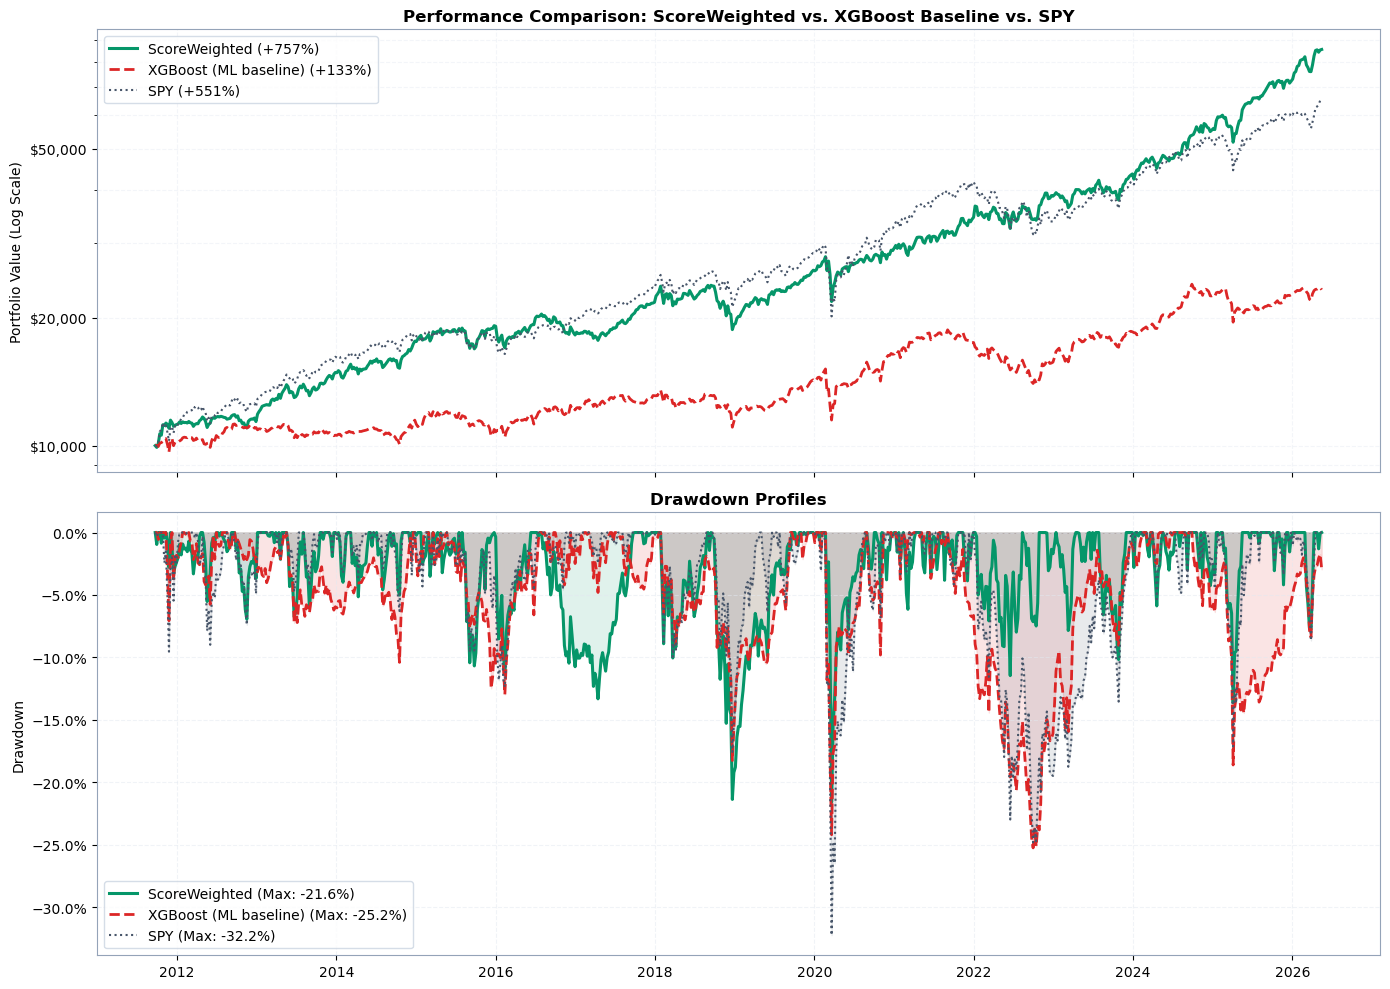

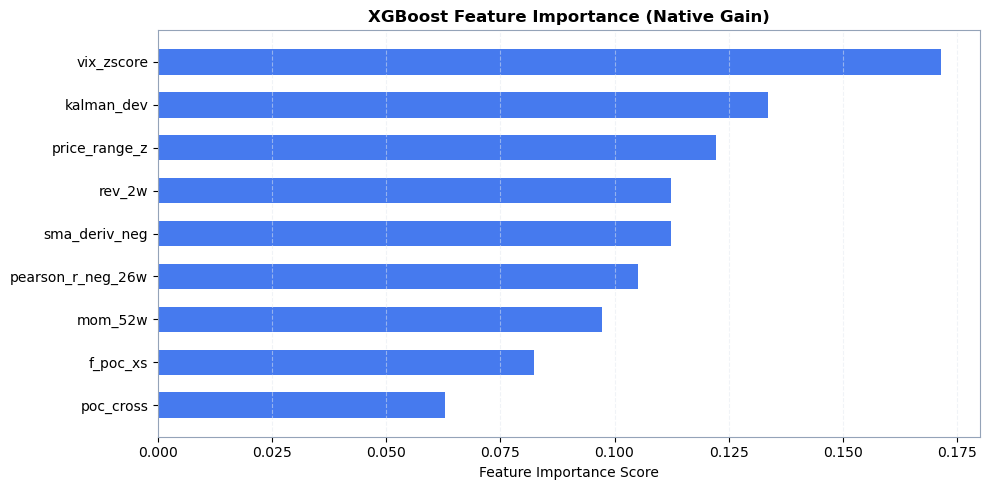

In [20]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# ── 1. Target e palette di colori ─────────────────────────────────────────────
TARGET_SERIES = ["ScoreWeighted", "XGBoost (ML baseline)", "SPY"]

PAL_CLEAN = {
    "ScoreWeighted":          ("#059669", 2.2, "-"),   # Verde smeraldo scuro
    "XGBoost (ML baseline)":  ("#dc2626", 2.0, "--"),  # Rosso nitido
    "SPY":                    ("#475569", 1.5, ":")    # Grigio lavagna
}

# We set the base style and white background for the figure
plt.style.use("default")  # Reset dello stile standard di matplotlib
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, facecolor="white")

# Force white background on individual axes
ax1.set_facecolor("white")
ax2.set_facecolor("white")

# upper panel — equity curves comparison
INITIAL_CAPITAL = 10_000  # Capitale iniziale desiderato

for name in TARGET_SERIES:
    s = P_with_xgb.get(name)
    if s is None or s.empty:
        continue

    s_aligned = s.reindex(common_xgb).fillna(0)

    # Explicit normalization: force the starting point at 10,000 regardless of equity
    eq_raw = equity(s_aligned)
    eq = (eq_raw / eq_raw.iloc[0]) * INITIAL_CAPITAL

    tot = eq.iloc[-1] / eq.iloc[0] - 1

    col, lw, ls = PAL_CLEAN[name]
    ax1.plot(eq.index, eq.values, color=col, lw=lw, ls=ls, label=f"{name} ({tot:+.0%})")

# Y-axis formatting (clean logarithmic scale)
ax1.set_yscale("log")

# Tick principali puliti (es. $10,000, $20,000, $50,000)
ax1.yaxis.set_major_locator(mticker.LogLocator(base=10.0, subs=(1.0, 2.0, 5.0)))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax1.yaxis.set_minor_formatter(mticker.NullFormatter())  # Rimuove tick secondari disordinati

ax1.set_title("Performance Comparison: ScoreWeighted vs. XGBoost Baseline vs. SPY", fontsize=12, fontweight="bold", color="black")
ax1.set_ylabel("Portfolio Value (Log Scale)", fontsize=10, color="black")
ax1.legend(fontsize=10, loc="upper left", frameon=True, facecolor="white", edgecolor="#cbd5e1")
ax1.grid(True, which="both", ls="--", alpha=0.4, color="#e2e8f0")

# ── 3. Lower Plot: Drawdown Comparison ────────────────────────────────────────
for name in TARGET_SERIES:
    s = P_with_xgb.get(name)
    if s is None or s.empty:
        continue

    s_aligned = s.reindex(common_xgb).fillna(0)
    dd = mdd_s(s_aligned)

    col, lw, ls = PAL_CLEAN[name]
    ax2.fill_between(dd.index, dd.values, 0, alpha=0.12, color=col)
    ax2.plot(dd.index, dd.values, color=col, lw=lw, ls=ls, label=f"{name} (Max: {dd.min():.1%})")

# Y-axis formatting (percentage)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax2.set_title("Drawdown Profiles", fontsize=12, fontweight="bold", color="black")
ax2.set_ylabel("Drawdown", fontsize=10, color="black")
ax2.legend(fontsize=10, loc="lower left", frameon=True, facecolor="white", edgecolor="#cbd5e1")
ax2.grid(True, ls="--", alpha=0.5, color="#e2e8f0")

# Axis border customization (spines)
for ax in [ax1, ax2]:
    for spine in ax.spines.values():
        spine.set_color("#94a3b8")
        spine.set_linewidth(0.8)

plt.tight_layout()

# ── 4. Save on white background (no transparency) ────────────────────────
plt.savefig(
    "figures/xgb_vs_scoreweighted_clean.png.png",
    bbox_inches="tight",
    dpi=300,
    facecolor="white",       
    edgecolor="none",
    transparent=False        
)
plt.show()


# ── 4. Feature Importance (XGBoost native gain) ──────────────────────────────
if xgb_model is not None:
    imp = pd.Series(
        xgb_model.feature_importances_,
        index=ALL_FEATURES
    ).sort_values(ascending=True)

    fig_imp, ax_imp = plt.subplots(figsize=(10, 5), facecolor="white")
    ax_imp.set_facecolor("white")

    # Barre orizzontali in blu nitido
    ax_imp.barh(imp.index, imp.values, color="#2563eb", alpha=0.85, height=0.6)

    ax_imp.set_title("XGBoost Feature Importance (Native Gain)", fontsize=12, fontweight="bold", color="black")
    ax_imp.set_xlabel("Feature Importance Score", fontsize=10, color="black")
    ax_imp.grid(True, axis="x", ls="--", alpha=0.5, color="#e2e8f0")


    for spine in ax_imp.spines.values():
        spine.set_color("#94a3b8")
        spine.set_linewidth(0.8)

    plt.tight_layout()

    # Save the second plot (Feature Importance) on white background
    plt.savefig(
        "figures/xgb_importance.png.png",
        bbox_inches="tight",
        dpi=300,
        facecolor="white",
        edgecolor="none",
        transparent=False
    )
    plt.show()

### LightGBM LambdaRank — cross-sectional ranking with purged CV tuning

Panel target: binned (5) cross-sectional percentile of excess weekly return;
CS features percentile-ranked, macro `vix_zscore` left raw. Parameters come from
a 30-trial random search over a 5-fold purged walk-forward CV (`helpers.random_search_lgb`).
The OOS loop retrains every `LGB_RETRAIN_EVERY` weeks and scores with the same
softmax×inverse-vol buffer portfolio (threshold 0.0).


In [21]:
import lightgbm as lgb
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import random

# feature list & macro/CS split
LGB_FEATURES = [
    "kalman_dev",
    "poc_cross",
    "sma_deriv_neg",
    "mom_52w",
    "rev_2w",
    "pearson_r_neg_26w",
    "f_poc_xs",
    "price_range_z",
    "vix_zscore",
]

# macro features are excluded from the cross-sectional rank step
MACRO_FEATURES = ["vix_zscore"]
CS_FEATURES    = [f for f in LGB_FEATURES if f not in MACRO_FEATURES]

K_LGB = 3   # top-K for the LambdaRank target
# ── Verifica che tutte le feature esistano in feat_raw ────────────────────────
_sample = ASSETS[0]
_avail  = feat_raw[_sample].columns.tolist() if _sample in feat_raw else []
_miss   = [f for f in LGB_FEATURES if f not in _avail]
if _miss:
    raise RuntimeError(
        f"Feature mancanti in feat_raw: {_miss}\n"
        "Re-run build_raw_features with the updated code."
    )
print(f"Feature check OK: {len(LGB_FEATURES)} feature trovate in feat_raw.")


# full-panel precomputation (excess returns & VIX interaction)
print("Precomputing full LGB panel...")
# FIX 4: Passiamo a n_bins=5 invece di 10
FULL_PANEL = build_lgb_panel(dates_full, ASSETS, feat_raw, ohlcv,
                               LGB_FEATURES, k_lgb=K_LGB)

if FULL_PANEL.empty:
    raise RuntimeError(
        "Empty panel — feat_raw does not contain the new features.\n"
        "Re-run build_raw_features with the updated code."
    )


_panel_date_index = FULL_PANEL.groupby("date").apply(lambda x: x.index.tolist())

# tuning — fixed params + random search

# monotonicity constraints — currently a no-op (vol_26w not in LGB_FEATURES); re-enable if that feature is added back
MONOTONE_CONSTRAINTS = [-1 if f == "vol_26w" else 0 for f in LGB_FEATURES]

FIXED_PARAMS = dict(
    objective                   = "lambdarank",
    metric                      = "ndcg",
    ndcg_eval_at                = [K_LGB],
    boosting_type               = "gbdt",
    lambdarank_truncation_level = 10,
    subsample_freq              = 1,
    random_state                = 42,
    verbose                     = -1,
    n_jobs                      = -1,
    mc                          = MONOTONE_CONSTRAINTS,
)

SEARCH_SPACE = {
    "max_depth"         : [3],
    "num_leaves"        : [7],
    "n_estimators"      : [250],
    "learning_rate"     : [0.025],
    "reg_lambda"        : [0.5],
    "reg_alpha"         : [0.0],
    "min_child_samples" : [15],
    "colsample_bytree"  : [0.70],
    "subsample"         : [0.80],
}

BUFFER_THRESHOLD = 0.000

MIN_TRAIN_ROWS = 400
LGB_SEED_WEEKS = 104
LGB_RETRAIN_EVERY = 13
OVERFIT_WINDOW = 26   # 6 mesi
MIN_TRAIN_DATES= 78

DEFAULT_PARAMS = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "ndcg_eval_at": [3, 5],            # evaluate top-3 and top-5 for stability
    "boosting_type": "gbdt",
    "lambdarank_truncation_level": 10,
    "max_depth": 3,
    "num_leaves": 7,
    "n_estimators": 150,
    "learning_rate": 0.015,
    "reg_lambda": 3.0,
    "reg_alpha": 0.1,                  
    "min_child_samples": 15,           # small value suits the ~21-asset cross-section
    "colsample_bytree": 0.60,          # higher fraction given only ~12 features
    "subsample": 0.8,
    "subsample_freq": 1,
    "random_state": 42,
    "verbose": -1,
    "n_jobs": -1,
}

# fixed IS/OOS split date for tuning
TUNING_CUTOFF_DATE = "2018-01-01"
panel_is = FULL_PANEL[FULL_PANEL["date"] < TUNING_CUTOFF_DATE]

print(f"Date IS per tuning (< {TUNING_CUTOFF_DATE}): {panel_is['date'].nunique()}")
print(f"Righe IS per tuning: {len(panel_is)}")

# FIX 3: Chiamata singola e pulita (eliminata la duplicazione)
if panel_is.empty or panel_is["date"].nunique() < 60:
    print("WARNING: panel IS troppo piccolo — uso DEFAULT_PARAMS")
    LGB_PARAMS = DEFAULT_PARAMS
else:
    LGB_PARAMS = random_search_lgb(panel_is, FIXED_PARAMS,
                                      SEARCH_SPACE, LGB_FEATURES,
                                      n_trials=30, n_cv_splits=5)

print(f"\nParametri finali per il walk-forward OOS:")
for k, v in LGB_PARAMS.items():
    print(f"  {k:<35} = {v}")


# walk-forward out-of-sample loop


lgb_model_v2        = None
lgb_last_train_v2   = -1
lgb_rets_v2         = {}
lgb_ic_list_v2      = []
lgb_selection_log   = {}

# Anti-turnover buffer for the LGB loop (helpers.BufferPortfolio); BUFFER_THRESHOLD defined above (=0.000)
lgb_bp = BufferPortfolio(cm, k=K1, buffer_threshold=BUFFER_THRESHOLD)

print(f"\nWalk-forward OOS LambdaRank ({len(LGB_FEATURES)} feature)...")
print(f"   Retrain ogni {LGB_RETRAIN_EVERY} settimane | warmup {LGB_SEED_WEEKS}w")
print("=" * 65)


for t in range(LGB_SEED_WEEKS, len(dates_full) - 1):
    dt      = dates_full[t]
    dt_prev = dates_full[t - 1]

    if (t - LGB_SEED_WEEKS) % 10 == 0:
        pct = (t - LGB_SEED_WEEKS) / max(len(dates_full) - 1 - LGB_SEED_WEEKS, 1) * 100
        print(f"   t={t} ({pct:.0f}%)  {pd.Timestamp(dt).date()}  "
              f"rets={len(lgb_rets_v2)}  "
              f"model={'OK' if lgb_model_v2 else 'None'}", flush=True)

    # ── Monitor IC ───────────────────────────────────────────────
    needs_retrain = (
        (t == LGB_SEED_WEEKS) or
        ((t - lgb_last_train_v2) >= LGB_RETRAIN_EVERY)
    )
    if len(lgb_ic_list_v2) >= OVERFIT_WINDOW:
        recent_ic = np.mean(lgb_ic_list_v2[-OVERFIT_WINDOW:])
        full_ic   = np.mean(lgb_ic_list_v2)
        if full_ic > 0.01 and recent_ic < full_ic * 0.5:
            print(f"   ⚠  [{pd.Timestamp(dt).date()}] Signal decay: "
                  f"IC recente={recent_ic:.4f} vs media={full_ic:.4f} — forzo retrain")
            needs_retrain = True

    # ── Retrain ───────────────────────────────────────────────────────────────
    if needs_retrain:
        panel = panel_upto(FULL_PANEL, dates_full, t)

        if not panel.empty and len(panel) >= MIN_TRAIN_ROWS:
            udates = sorted(panel["date"].unique())

            if len(udates) >= MIN_TRAIN_DATES:
                split_dt = udates[-VAL_DATES]
                tr = panel[panel["date"] <  split_dt].sort_values("date")
                va = panel[panel["date"] >= split_dt].sort_values("date")

                if len(tr) >= 2 and len(va) >= 2:
                    X_tr = tr[LGB_FEATURES].values.astype(np.float32)
                    y_tr = tr["y_rel"].values.astype(int)
                    X_va = va[LGB_FEATURES].values.astype(np.float32)
                    y_va = va["y_rel"].values.astype(int)

                    group_tr = tr.groupby("date", sort=False).size().values
                    group_va = va.groupby("date", sort=False).size().values



                    evals_result = {}   # populated by LightGBM during training

                    model = lgb.LGBMRanker(**LGB_PARAMS)
                    model.fit(
                        X_tr, y_tr, group=group_tr,
                        eval_set=[(X_tr, y_tr), (X_va, y_va)],
                        eval_group=[group_tr, group_va],
                        eval_names=["train", "val"],
                        callbacks=[
                            lgb.early_stopping(50, verbose=False),
                            lgb.record_evaluation(evals_result),  # record the eval curve
                        ],
                    )
                    lgb_model_v2      = model
                    lgb_last_train_v2 = t
                    LAST_EVALS_RESULT = evals_result   # keep for the learning-curve plot

                    print(f"   [{pd.Timestamp(dt).date()}] Retrain | "
                          f"best_iter={model.best_iteration_} | "
                          f"train={len(tr)} val={len(va)}")

    if lgb_model_v2 is None:
        continue

    # weekly OOS scoring
    current_feats, actual_rets = {}, {}

    for tkr in ASSETS:
        if tkr not in feat_raw:
            continue
        if not all(f in feat_raw[tkr].columns for f in LGB_FEATURES):
            continue
        try:
            vals = extract_features_at(feat_raw, tkr, dt_prev, LGB_FEATURES,
                                       reject_inf=False)
            if vals is not None:
                current_feats[tkr] = vals
            cl  = ohlcv[tkr]["Close"]
            loc = cl.index.get_loc(dt_prev)
            if loc + 1 < len(cl):
                p0, p1 = cl.iloc[loc], cl.iloc[loc + 1]
                if p0 > 0 and not pd.isna(p1):
                    actual_rets[tkr] = np.log(p1 / p0)
        except KeyError:
            continue

    if len(current_feats) < K_LGB:
        continue

    # cross-sectional rank on CS features only
    df_curr = pd.DataFrame(current_feats, index=LGB_FEATURES).T
    df_curr = apply_cs_rank(df_curr, CS_FEATURES)

    # raw score prediction
    preds = lgb_model_v2.predict(df_curr[LGB_FEATURES].values.astype(np.float32))
    raw_scores = dict(zip(df_curr.index, preds))

    scores = raw_scores

    # weekly OOS IC of the final signal
    ic_val = weekly_ic(scores, pd.Series(actual_rets), min_n=5)
    if not np.isnan(ic_val):
        lgb_ic_list_v2.append(ic_val)


    ret = lgb_bp.step(scores, t)
    if ret is not None:
        lgb_rets_v2[dt] = ret
        lgb_selection_log[dt] = list(lgb_bp.last)

lgb_series_v2 = pd.Series(lgb_rets_v2).sort_index()

# final diagnostics

print(f"\nLambdaRank OOS completato: {len(lgb_series_v2)} settimane.")

if lgb_ic_list_v2:
    arr     = np.array(lgb_ic_list_v2)
    mean_ic = arr.mean()
    std_ic  = arr.std()
    ic_ir   = icir(lgb_ic_list_v2)
    pct_pos = (arr > 0).mean()

    print(f"\n{'='*55}")
    print(f"  DIAGNOSTICA SIGNAL — LambdaRank OOS")
    print(f"{'='*55}")
    print(f"  Settimane con IC : {len(arr)}")
    print(f"  Mean IC          : {mean_ic:+.4f}")
    print(f"  Std IC           : {std_ic:.4f}")
    print(f"  ICIR             : {ic_ir:+.4f}")
    print(f"  IC > 0 (hit)     : {pct_pos:.1%}")

    if mean_ic > 0.03 and ic_ir > 0.3:
        verdict = "Robust signal: positive and stable alpha."
    elif mean_ic > 0.01:
        verdict = "Weak but positive signal: monitor stability."
    else:
        verdict = "IC close to zero: the model does not rank returns."
    print(f"\n  → {verdict}")
    print(f"{'='*55}")


Feature check OK: 9 feature trovate in feat_raw.
Precomputing full LGB panel...
  Panel completo: 18207 righe | 867 date | 9 feature
Date IS per tuning (< 2018-01-01): 431
Righe IS per tuning: 9051
Random search: 30 trial | 5-fold purged CV
Panel IS: 9051 righe | 431 date
  [01/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [02/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [03/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [04/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [05/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [06/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [07/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [08/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [09/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [10/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [11/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [12/30] ICIR=+0.3408 | depth=3 leaves=7 λ=0.5 min_ch=15
  [13/30] ICIR=+0.3408 | depth=

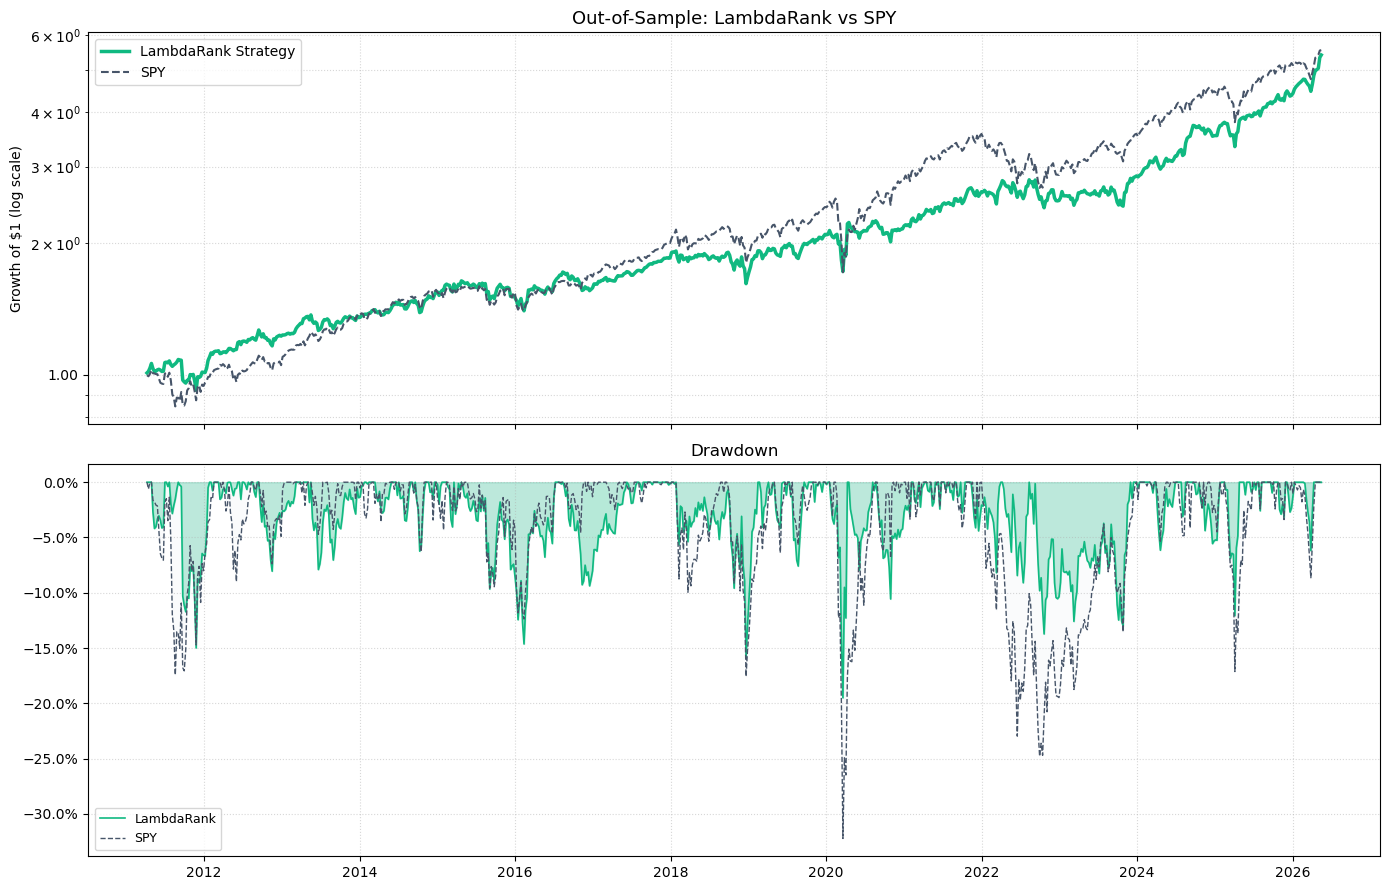


PERFORMANCE COMPARISON — LambdaRank vs SPY
         LambdaRank      SPY
CAGR         11.77%   11.96%
Ann. Vol     14.60%   16.23%
Sharpe        0.835    0.778
Sortino       1.355    1.127
Max DD      -19.50%  -32.23%
Hit Rate      57.7%    57.9%


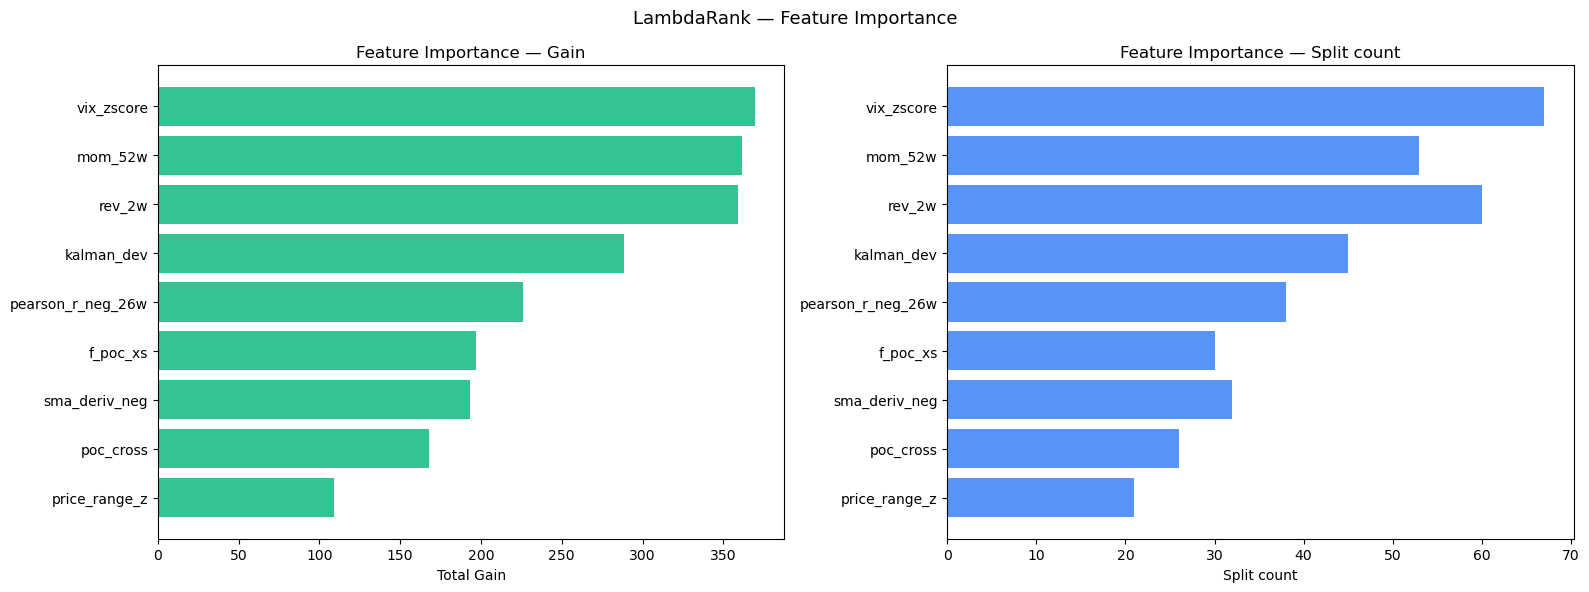

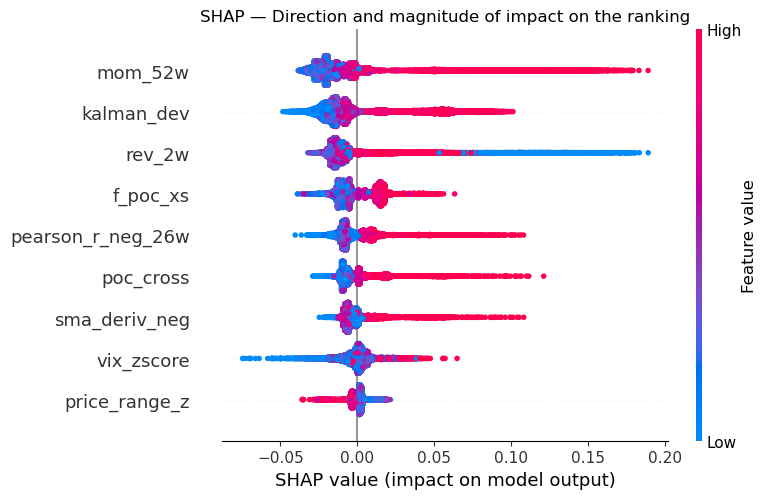

In [22]:
# SECTION 6 — Visualizzazione OOS: LightGBM vs SPY
import shap

# SPY returns on the same OOS dates
cl_spy = ohlcv["SPY"]["Close"]

spy_weekly_prices = cl_spy.reindex(lgb_series_v2.index, method="ffill")
spy_series_lgb = spy_weekly_prices.pct_change().dropna()

common_idx = lgb_series_v2.index.intersection(spy_series_lgb.index)
lgb_aligned = lgb_series_v2.loc[common_idx]
spy_aligned = spy_series_lgb.loc[common_idx]


# equity curves & drawdown plot
cum_lgb = (1 + lgb_aligned).cumprod()
cum_spy = (1 + spy_aligned).cumprod()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(cum_lgb.index, cum_lgb.values,
             color="#10b981", lw=2.5, label="LambdaRank Strategy")
axes[0].plot(cum_spy.index, cum_spy.values,
             color="#475569", lw=1.5, ls="--", label="SPY")
axes[0].grid(True, which="both", ls=":", alpha=0.5)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.2f}"))
axes[0].set_title("Out-of-Sample: LambdaRank vs SPY", fontsize=13)
axes[0].set_ylabel("Growth of $1 (log scale)")
axes[0].legend(fontsize=10)

# Drawdown
dd_lgb = mdd_s(lgb_aligned).astype(float)
dd_spy = mdd_s(spy_aligned).astype(float)
axes[1].fill_between(dd_lgb.index, dd_lgb.values, 0, alpha=0.3, color="#10b981")
axes[1].plot(dd_lgb.index, dd_lgb.values, color="#10b981", lw=1.2, label="LambdaRank")
axes[1].fill_between(dd_spy.index, dd_spy.values, 0, alpha=0.15, color="#e2e8f0")
axes[1].plot(dd_spy.index, dd_spy.values, color="#475569", lw=1.0, ls="--", label="SPY")
axes[1].grid(True, which="both", ls=":", alpha=0.5)
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_title("Drawdown")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("figures/lgb_equity_drawdown.png.png", bbox_inches="tight", dpi=150)
plt.show()

# ── 3. Metrics table ──────────────────────────────────────────────────────────
print("\n" + "=" * 50)
print("PERFORMANCE COMPARISON — LambdaRank vs SPY")
print("=" * 50)
print(
    pd.DataFrame(
        {
            "LambdaRank": calc_metrics(lgb_aligned),
            "SPY": calc_metrics(spy_aligned),
        }
    ).to_string()
)

# ── 4. Feature Importance (Gain + Split) ─────────────────────────────────────
importance_gain  = lgb_model_v2.booster_.feature_importance(importance_type="gain")
importance_split = lgb_model_v2.booster_.feature_importance(importance_type="split")

df_imp = pd.DataFrame({
    "Feature": LGB_FEATURES,
    "Gain"   : importance_gain,
    "Split"  : importance_split,
}).sort_values("Gain", ascending=True)   # ascending for horizontal bars

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(df_imp["Feature"], df_imp["Gain"],  color="#10b981", alpha=0.85)
axes[0].set_title("Feature Importance — Gain", fontsize=12)
axes[0].set_xlabel("Total Gain")

axes[1].barh(df_imp["Feature"], df_imp["Split"], color="#3b82f6", alpha=0.85)
axes[1].set_title("Feature Importance — Split count", fontsize=12)
axes[1].set_xlabel("Split count")

plt.suptitle("LambdaRank — Feature Importance", fontsize=13)
plt.tight_layout()
plt.savefig("figures/lgb_feature_importance.png.png", bbox_inches="tight", dpi=150)
plt.show()

# ── 5. SHAP Summary Plot ──────────────────────────────────────────────────────
# Usa FULL_PANEL già precalcolato — nessun rebuild
X_shap = FULL_PANEL[LGB_FEATURES].values.astype(np.float32)

explainer   = shap.TreeExplainer(lgb_model_v2)
shap_values = explainer.shap_values(X_shap)

fig, ax = plt.subplots(figsize=(10, 6))
plt.sca(ax)
shap.summary_plot(shap_values, X_shap,
                  feature_names=LGB_FEATURES,
                  plot_type="dot", show=False)
ax.set_title("SHAP — Direction and magnitude of impact on the ranking", fontsize=12)
plt.tight_layout()
plt.savefig("figures/lgb_shap.png.png", bbox_inches="tight", dpi=150)
plt.show()


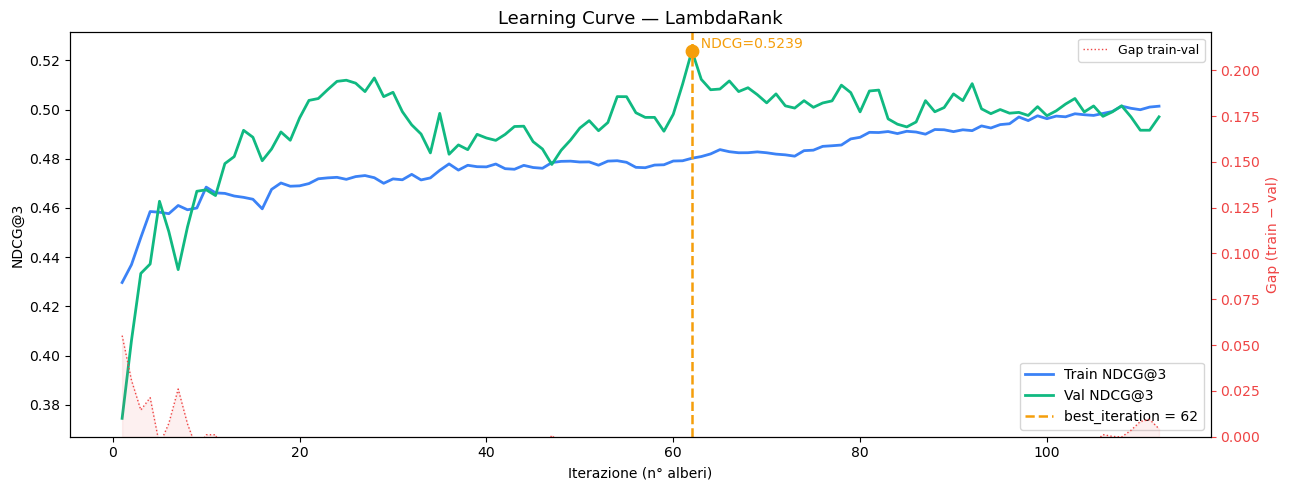

  Iterazioni totali  : 112
  best_iteration_    : 62
  Train NDCG@best    : 0.4802
  Val   NDCG@best    : 0.5239
  Gap @best          : -0.0437
  Gap/Val ratio      : -0.083  ✓ ok


In [23]:
# learning-curve plot (runs after the walk-forward)
plot_learning_curve(LAST_EVALS_RESULT, lgb_model_v2.best_iteration_)


In [26]:
# ML audit report
import textwrap

SEP  = "=" * 70
sep  = "-" * 70

print(SEP)
print("  ML AUDIT REPORT — LambdaRank Walk-Forward")
print(SEP)

# ── 0. Setup ──────────────────────────────────────────────────────────────────
common_idx  = lgb_series_v2.index.intersection(spy_series_lgb.index)
lgb_aligned = lgb_series_v2.loc[common_idx]
spy_aligned = spy_series_lgb.loc[common_idx]

# ── 1. Dataset Stats ──────────────────────────────────────────────────────────
print("\n[1] DATASET")
print(sep)
print(f"  Totale asset              : {len(ASSETS)}")
print(f"  Feature usate             : {len(LGB_FEATURES)}")
print(f"  Feature list              : {LGB_FEATURES}")
print(f"  Panel totale righe        : {len(FULL_PANEL)}")
print(f"  Panel date uniche         : {FULL_PANEL['date'].nunique()}")
print(f"  Panel range date          : {FULL_PANEL['date'].min().date()} -> {FULL_PANEL['date'].max().date()}")
print(f"  Asset medi per step       : {len(FULL_PANEL)/FULL_PANEL['date'].nunique():.1f}")
print(f"  LGB_SEED_WEEKS            : {LGB_SEED_WEEKS}")
print(f"  XGB_RETRAIN_EVERY         : {LGB_RETRAIN_EVERY}")
print(f"  MIN_TRAIN_ROWS            : {MIN_TRAIN_ROWS}")
print(f"  VAL_DATES                 : {VAL_DATES}")

# target (y_rel) distribution
print(f"\n  Target y_rel distribuzione:")
vc = FULL_PANEL["y_rel"].value_counts().sort_index()
for decile, count in vc.items():
    pct = count / len(FULL_PANEL) * 100
    print(f"    decile {decile}: {count:>5} righe ({pct:.1f}%)")

# model parameters (post-tuning)
print(f"\n[2] PARAMETRI MODELLO (post-tuning)")
print(sep)
for k, v in LGB_PARAMS.items():
    print(f"  {k:<35} = {v}")
print(f"  best_iteration_           = {lgb_model_v2.best_iteration_}")

# ── 3. Feature Importance ─────────────────────────────────────────────────────
print(f"\n[3] FEATURE IMPORTANCE")
print(sep)
gain  = lgb_model_v2.booster_.feature_importance(importance_type="gain")
split = lgb_model_v2.booster_.feature_importance(importance_type="split")
df_imp = pd.DataFrame({
    "feature": LGB_FEATURES,
    "gain"   : gain,
    "split"  : split,
    "gain_pct" : gain  / (gain.sum()  + 1e-10) * 100,
    "split_pct": split / (split.sum() + 1e-10) * 100,
}).sort_values("gain", ascending=False).reset_index(drop=True)
print(f"  {'Rank':<5} {'Feature':<22} {'Gain':>10} {'Gain%':>7} {'Split':>8} {'Split%':>8}")
print(f"  {'-'*63}")
for _, row in df_imp.iterrows():
    print(f"  {int(_)+1:<5} {row['feature']:<22} {row['gain']:>10.1f} "
          f"{row['gain_pct']:>6.1f}% {int(row['split']):>8} {row['split_pct']:>7.1f}%")

# ── 3B. Root Split Distribution (Prima decisione degli alberi) ───────────────
print(f"\n[3B] ROOT SPLIT DISTRIBUTION")
print(sep)
booster = lgb_model_v2.booster_
trees   = booster.dump_model()["tree_info"]

root_features = []
for t in trees:
    if "split_feature" in t["tree_structure"]:
        sf = t["tree_structure"]["split_feature"]
        # handle both numeric index and string feature name
        feat_name = LGB_FEATURES[sf] if isinstance(sf, int) else sf
        root_features.append(feat_name)

if root_features:
    from collections import Counter
    print("  Feature chosen as root split (first node):")
    for feat, cnt in Counter(root_features).most_common():
        pct = cnt / len(trees) * 100
        print(f"    {feat:<25}: {cnt:>3} volte ({pct:.1f}%)")

# features with zero gain (never used)
dead = df_imp[df_imp["gain"] == 0]["feature"].tolist()
if dead:
    print(f"\n  ⚠  Feature con Gain=0 (mai usate): {dead}")
else:
    print(f"\n  Tutte le feature usate almeno una volta.")

# ── 4. Signal Quality: IC OOS ────────────────────────────────────────────────
print(f"\n[4] SIGNAL QUALITY — IC OOS")
print(sep)
if lgb_ic_list_v2:
    arr = np.array(lgb_ic_list_v2)
    q   = np.percentile(arr, [5, 25, 50, 75, 95])
    print(f"  Settimane con IC          : {len(arr)}")
    print(f"  Mean IC                   : {arr.mean():+.4f}")
    print(f"  Std IC                    : {arr.std():.4f}")
    print(f"  ICIR (mean/std)           : {arr.mean()/(arr.std()+1e-10):+.4f}")
    print(f"  IC > 0                    : {(arr>0).mean():.1%}")
    print(f"  Percentili [5,25,50,75,95]: "
          f"{q[0]:+.3f} {q[1]:+.3f} {q[2]:+.3f} {q[3]:+.3f} {q[4]:+.3f}")
    # mean IC by year
    ic_s = pd.Series(lgb_ic_list_v2, index=lgb_series_v2.index[:len(lgb_ic_list_v2)])
    print(f"\n  IC medio per anno:")
    for yr, grp in ic_s.groupby(ic_s.index.year):
        print(f"    {yr}: mean={grp.mean():+.4f}  std={grp.std():.4f}  "
              f"ICIR={grp.mean()/(grp.std()+1e-10):+.3f}  n={len(grp)}")
else:
    print("  NESSUN IC calcolato — pipeline vuota.")

# ── 4B. IC vs Market Regimes (VIX) ───────────────────────────────────────────
print(f"\n[4B] IC BY VOLATILITY REGIME (VIX)")
print(sep)
if 'vix_weekly' in locals() and lgb_ic_list_v2:
    # build the IC series on real OOS dates
    ic_s  = pd.Series(lgb_ic_list_v2, index=lgb_series_v2.index[:len(lgb_ic_list_v2)])
    vix_s = vix_weekly.reindex(ic_s.index).ffill()

    vix_median = vix_s.median()
    ic_hi_vix  = ic_s[vix_s > vix_median].mean()
    ic_lo_vix  = ic_s[vix_s <= vix_median].mean()

    print(f"  VIX Median OOS                    : {vix_median:.2f}")
    print(f"  Mean IC con VIX Alto  (> {vix_median:.1f}) : {ic_hi_vix:+.4f}")
    print(f"  Mean IC con VIX Basso (<= {vix_median:.1f}) : {ic_lo_vix:+.4f}")

    diff = ic_hi_vix - ic_lo_vix
    if abs(diff) > 0.02:
        regime_note = "Regime sensitivity: the model performs differently depending on vol."
    else:
        regime_note = "Regime stability: homogeneous performance across high and low vol."
    print(f"  → {regime_note}")
else:
    print("  ⚠ vix_weekly series not found — regime analysis skipped.")
# ── 5. Return Stats OOS ──────────────────────────────────────────────────────
print(f"\n[5] RETURN STATS OOS")
print(sep)

print_perf_report(lgb_aligned, "LambdaRank")
print()
print_perf_report(spy_aligned, "SPY benchmark")

# Alpha vs SPY
_ab = alpha_vs_benchmark(lgb_aligned, spy_aligned)
alpha_ann = _ab["alpha_ann"]
ir        = _ab["ir"]
print(f"\n  [Alpha vs SPY]")
print(f"    Alpha ann.    : {alpha_ann:+.2%}")
print(f"    Info Ratio    : {ir:+.3f}")
print(f"    % settimane > SPY : {(lgb_aligned > spy_aligned).mean():.1%}")


# ── 5B. REAL ASSET TURNOVER & EXECUTABILITY ──────────────────────────────────
print(f"\n[5B] REAL ASSET TURNOVER & EXECUTABILITY")
print("=" * 55)

if lgb_selection_log:
    dates_sel = sorted(lgb_selection_log.keys())

    # substitution turnover
    turnovers_substitution = []
    for i in range(1, len(dates_sel)):
        prev = set(lgb_selection_log[dates_sel[i-1]])
        curr = set(lgb_selection_log[dates_sel[i]])
        changed = len(curr - prev)
        turnovers_substitution.append(changed / max(len(curr), 1))

    avg_to_sub = np.mean(turnovers_substitution)

    # drift turnover: start equal-weight, prices move the weights, then rebalance to target
    # cost = sum(|w_drifted - w_target|)/2  (one-way turnover)
    turnovers_drift = []

    for i in range(1, len(dates_sel)):
        dt_prev = dates_sel[i - 1]
        dt_curr = dates_sel[i]

        held = set(lgb_selection_log[dt_prev])
        k = len(held)
        if k == 0:
            continue

        # initial equal weights
        w0 = {tkr: 1.0 / k for tkr in held}

        # each held asset's return over the week
        rets_week = {}
        for tkr in held:
            try:
                cl = ohlcv[tkr]["Close"]
                loc_prev = cl.index.get_loc(dt_prev)
                loc_curr = cl.index.get_loc(dt_curr)
                p0 = cl.iloc[loc_prev]
                p1 = cl.iloc[loc_curr]
                if p0 > 0 and not pd.isna(p1):
                    rets_week[tkr] = p1 / p0  # gross return (non log)
            except (KeyError, IndexError):
                continue

        if len(rets_week) < k:
            continue

        # post-drift weights
        w_gross = {tkr: w0[tkr] * rets_week[tkr] for tkr in rets_week}
        total = sum(w_gross.values())
        if total <= 0:
            continue
        w_drifted = {tkr: v / total for tkr, v in w_gross.items()}

        # target: equal weight on the newly selected assets
        new_held = set(lgb_selection_log[dt_curr])
        k_new = len(new_held)
        w_target = {tkr: 1.0 / k_new for tkr in new_held}

        # total turnover (drift + substitution)
        all_tkrs = held | new_held
        to_total = sum(
            abs(w_drifted.get(tkr, 0.0) - w_target.get(tkr, 0.0))
            for tkr in all_tkrs
        ) / 2.0

        # drift-only turnover (assets kept in the portfolio)
        kept = held & new_held
        to_drift = sum(
            abs(w_drifted.get(tkr, 0.0) - w_target.get(tkr, 0.0))
            for tkr in kept
        ) / 2.0

        turnovers_drift.append({"total": to_total, "drift_only": to_drift})

    # commission cost estimate
    COMMISSION_BPS = 5
    commission = COMMISSION_BPS / 10_000

    avg_to_total  = np.mean([x["total"]      for x in turnovers_drift])
    avg_to_drift  = np.mean([x["drift_only"] for x in turnovers_drift])
    avg_to_sub_v2 = avg_to_total - avg_to_drift  # implied substitution turnover

    ann_drag_total = avg_to_total * commission * 52
    ann_drag_drift = avg_to_drift * commission * 52
    ann_drag_sub   = avg_to_sub_v2 * commission * 52

    print(f"\n  {'─'*50}")
    print(f"  TURNOVER FROM ASSET REPLACEMENT")
    print(f"  {'─'*50}")
    print(f"  Assets in portfolio (K)           : {K_LGB}")
    print(f"  Average weekly turnover           : {avg_to_sub:.1%}")
    print(f"  Average assets changed            : {avg_to_sub * K_LGB:.2f} out of {K_LGB}")
    print(f"  Average holding period            : {1/(avg_to_sub+1e-5):.1f} weeks")
    print(f"  Weeks with no changes             : "
          f"{sum(1 for t in turnovers_substitution if t==0)} "
          f"({sum(1 for t in turnovers_substitution if t==0)/len(turnovers_substitution):.1%})")

    print(f"\n  {'─'*50}")
    print(f"  TURNOVER FROM WEIGHT DRIFT (rebalancing)")
    print(f"  {'─'*50}")
    print(f"  Average turnover (drift only)     : {avg_to_drift:.1%}")
    print(f"  Average turnover (total)          : {avg_to_total:.1%}")
    print(f"  Commission applied                : {COMMISSION_BPS} bps one-way")
    print(f"\n  {'─'*50}")
    print(f"  ESTIMATED ANNUALIZED DRAG")
    print(f"  {'─'*50}")
    print(f"  From asset replacement            : {ann_drag_sub:.3%}")
    print(f"  From drift/rebalancing            : {ann_drag_drift:.3%}")
    print(f"  TOTAL estimated annual drag       : {ann_drag_total:.3%}")
    print(f"  (over 52 weeks, {COMMISSION_BPS}bps one-way)")

else:
    print("  ⚠ lgb_selection_log vuoto.")

# ── 6. Return per anno ────────────────────────────────────────────────────────
print(f"\n[6] RETURN PER ANNO")
print(sep)
print(f"  {'Anno':<6} {'LambdaRank':>12} {'SPY':>8} {'Alpha':>8}")
print(f"  {'-'*38}")
for yr in sorted(lgb_aligned.index.year.unique()):
    l = lgb_aligned[lgb_aligned.index.year == yr]
    s = spy_aligned[spy_aligned.index.year == yr]
    lr = (1+l).prod()-1
    sr = (1+s).prod()-1
    print(f"  {yr:<6} {lr:>+12.2%} {sr:>+8.2%} {lr-sr:>+8.2%}")

# ── 7. Retrain log ────────────────────────────────────────────────────────────
print(f"\n[7] RETRAIN LOG")
print(sep)
print(f"  Ultimo retrain a t        : {lgb_last_train_v2}")
print(f"  Data ultimo retrain       : {dates_full[lgb_last_train_v2].date()}")
n_retrains = max(1, (len(dates_full)-1-LGB_SEED_WEEKS) // XGB_RETRAIN_EVERY)
print(f"  Retrains stimati          : ~{n_retrains}")


# ── 8. Diagnostica panel IS usato per tuning ──────────────────────────────────
print(f"\n[8] PANEL IS (usato per tuning)")
print(sep)

if 'TUNING_CUTOFF_DATE' in locals():
    panel_is_check = FULL_PANEL[FULL_PANEL["date"] < TUNING_CUTOFF_DATE]
else:
    # fallback when TUNING_CUTOFF_DATE is unavailable
    panel_is_check = FULL_PANEL[FULL_PANEL["date"] < dates_full[LGB_SEED_WEEKS]]

print(f"  Righe                     : {len(panel_is_check)}")
print(f"  Date uniche               : {panel_is_check['date'].nunique()}")

if not panel_is_check.empty:
    print(f"  Range                     : {panel_is_check['date'].min().date()} -> "
          f"{panel_is_check['date'].max().date()}")
    print(f"  NaN per feature:")
    for f in LGB_FEATURES:
        pct_nan = panel_is_check[f].isna().mean() * 100
        flag = " ⚠" if pct_nan > 5 else ""
        print(f"    {f:<25}: {pct_nan:.1f}%{flag}")
else:
    print("  ⚠ PANEL IS EMPTY: check the TUNING_CUTOFF_DATE variable or the dates in FULL_PANEL.")

# ── 9. MODEL SCORE & STABILITY DIAGNOSTICS ───────────────────────────────────
print(f"\n[9] MODEL SCORE & STABILITY DIAGNOSTICS")
print(sep)
# scores predicted over the full OOS panel
oos_panel = FULL_PANEL[FULL_PANEL["date"] >= dates_full[LGB_SEED_WEEKS]]

if not oos_panel.empty:
    all_scores = lgb_model_v2.predict(oos_panel[LGB_FEATURES].values.astype(np.float32))
    print(f"  Totale predizioni OOS      : {len(all_scores)}")
    print(f"  Score OOS Mean             : {np.mean(all_scores):+.4f}")
    print(f"  Score OOS Std              : {np.std(all_scores):.4f}")
    print(f"  Score OOS Min / Max        : {np.min(all_scores):+.4f} / {np.max(all_scores):+.4f}")
    print(f"  Percentili [5, 50, 95]     : {np.percentile(all_scores, 5):+.4f} | "
          f"{np.percentile(all_scores, 50):+.4f} | {np.percentile(all_scores, 95):+.4f}")

    if np.std(all_scores) < 0.01:
        print("  ⚠ WARNING: Scores almost flat (Std < 0.01). The model struggles to separate the assets.")
    else:
        print("  → Healthy score distribution: good dispersion between winners and losers.")
else:
    print("  ⚠ OOS panel not found.")

# ── 10A. TREE STRUCTURE DIAGNOSTICS ──────────────────────────────────────────
print(f"\n[10A] TREE STRUCTURE & LEAF DENSITY")
print(sep)

# tree structure from the LightGBM booster
booster_df = lgb_model_v2.booster_.dump_model()
num_trees = len(booster_df['tree_info'])

leaf_counts = [tree['num_leaves'] for tree in booster_df['tree_info']]
max_depths = [tree['tree_structure'].get('max_depth', 3) for tree in booster_df['tree_info']]

print(f"  Numero totale di alberi (estimators) : {num_trees}")
print(f"  Media foglie per albero              : {np.mean(leaf_counts):.2f} / {lgb_model_v2.num_leaves}")
print(f"  Foglie min / max utilizzate          : {np.min(leaf_counts)} / {np.max(leaf_counts)}")

if np.mean(leaf_counts) < 3:
    print("  ⚠ WARNING: Trees too simple (almost stumps). Risk of underfitting.")
elif np.mean(leaf_counts) >= lgb_model_v2.num_leaves - 1:
    print("  → Trees saturate maximum capacity (complex and rich structure).")

# ── 10B. FEATURE INTERACTION & SPLIT PATHS ────────────────────────────────────
print(f"\n[10B] TOP BRANCH SPLIT PARENTS & CHILDREN (FEATURE INTERACTIONS)")
print(sep)

import json

def get_splits(node):
    splits = []
    if 'split_feature' in node:
        feat = LGB_FEATURES[node['split_feature']]
        if 'left_child' in node and 'split_feature' in node['left_child']:
            left_feat = LGB_FEATURES[node['left_child']['split_feature']]
            splits.append((feat, left_feat))
        if 'right_child' in node and 'split_feature' in node['right_child']:
            right_feat = LGB_FEATURES[node['right_child']['split_feature']]
            splits.append((feat, right_feat))
        # recurse into children
        if 'left_child' in node:
            splits.extend(get_splits(node['left_child']))
        if 'right_child' in node:
            splits.extend(get_splits(node['right_child']))
    return splits

all_interactions = []
for tree in booster_df['tree_info']:
    all_interactions.extend(get_splits(tree['tree_structure']))

from collections import Counter
interaction_counts = Counter(all_interactions).most_common(5)

print("  The 5 most frequent interactions / branches (Parent Node ➔ Child Node):")
for (parent, child), count in interaction_counts:
    print(f"    • {parent:<15} ➔ {child:<15} : {count} volte")

# ── 10C. TOP-K SCORE SEPARATION GAP ──────────────────────────────────────────
print(f"\n[10C] PORTFOLIO SEPARATION CONVICTION (TOP-K GAP)")
print(sep)

gaps = []
oos_panel = FULL_PANEL[FULL_PANEL["date"] >= dates_full[LGB_SEED_WEEKS]]

for dt in oos_panel['date'].unique():
    df_dt = oos_panel[oos_panel['date'] == dt]
    if len(df_dt) >= K_LGB + 1:
        preds = lgb_model_v2.predict(df_dt[LGB_FEATURES].values.astype(np.float32))
        sorted_preds = np.sort(preds)[::-1]

        # Gap tra il 3° e il 4° asset
        gap = sorted_preds[K_LGB - 1] - sorted_preds[K_LGB]
        gaps.append(gap)

avg_gap = np.mean(gaps)
std_gap = np.std(gaps)

print(f"  Gap medio Score tra 3° e 4° asset : {avg_gap:+.4f} (±{std_gap:.4f})")
if avg_gap < 0.02:
    print("  ⚠ LOW CONVICTION: The 3rd and 4th assets are almost identical to the model.")
    print("     tiny data changes cause high turnover between who enters and who exits.")
else:
    print("  → GOOD CONVICTION: There is a clear separation between the Top-3 and the excluded.")

# ── 10D. SCORE MONOTONICITY & DECILE RETURNS ─────────────────────────────────
print(f"\n[10D] SCORE MONOTONICITY (PREDICTED SCORE VS REAL RETURNS)")
print(sep)

RET_COL = "y_rel"
if RET_COL in oos_panel.columns:
    oos_panel_copy = oos_panel.copy()
    oos_panel_copy['pred_score'] = lgb_model_v2.predict(
        oos_panel_copy[LGB_FEATURES].values.astype(np.float32)
    )

    # Numero di bin adattivo: tenta 5, scende se score troppo concentrati
    LABELS_5 = ["Q1 (Worst)", "Q2", "Q3", "Q4", "Q5 (Best)"]
    for n_bins in [5, 4, 3]:
        try:
            labels = LABELS_5[:n_bins]
            oos_panel_copy['quintile'] = pd.qcut(
                oos_panel_copy['pred_score'],
                q=n_bins,
                labels=labels,
                duplicates='drop'
            )
            if oos_panel_copy['quintile'].nunique() >= 2:
                break
        except ValueError:
            continue
    else:
        print("  ⚠ Scores too concentrated to create meaningful quintiles.")
        oos_panel_copy['quintile'] = None

    if oos_panel_copy['quintile'].notna().any():
        quintile_perf = oos_panel_copy.groupby('quintile', observed=True)['y_rel'].mean()

        print("  Average real 1-week return by Score Quintile:")
        for q, ret in quintile_perf.items():
            print(f"    • {q:<12} : {ret:+.3f}")

        is_monotonic = quintile_perf.is_monotonic_increasing
        if is_monotonic:
            print("\n  → EXCELLENT RESULT: The model is MONOTONIC (Q5 > Q4 > ... > Q1).")
        else:
            print("\n  ⚠ IMPERFECT MONOTONICITY: Inversions between middle quintiles.")
else:
    print(f"  ⚠ Colonna '{RET_COL}' non trovata nel panel.")


  ML AUDIT REPORT — LambdaRank Walk-Forward

[1] DATASET
----------------------------------------------------------------------
  Totale asset              : 21
  Feature usate             : 9
  Feature list              : ['kalman_dev', 'poc_cross', 'sma_deriv_neg', 'mom_52w', 'rev_2w', 'pearson_r_neg_26w', 'f_poc_xs', 'price_range_z', 'vix_zscore']
  Panel totale righe        : 18207
  Panel date uniche         : 867
  Panel range date          : 2009-10-02 -> 2026-05-08
  Asset medi per step       : 21.0
  LGB_SEED_WEEKS            : 104
  XGB_RETRAIN_EVERY         : 13
  MIN_TRAIN_ROWS            : 400
  VAL_DATES                 : 52

  Target y_rel distribuzione:
    decile 0:  3468 righe (19.0%)
    decile 1:  3468 righe (19.0%)
    decile 2:  3468 righe (19.0%)
    decile 3:  3468 righe (19.0%)
    decile 4:  4335 righe (23.8%)

[2] PARAMETRI MODELLO (post-tuning)
----------------------------------------------------------------------
  objective                           = lamb

# Appendix A — Strategy vs SPY: full statistical test suite

Complete comparison of the baseline strategy (Equal 0.5 + ScoreWeighted, OOS gross) against SPY, split **Pre** (< 2022-01-01) / **Post** (= OOS 2022–26) and **Full**: per-series metrics, tail risk (VaR/ES), CAPM & Treynor-Mazuy alpha with HAC errors, structural-break test and distribution-similarity tests (KS / Levene).

Aligned observations: 845 (dropped 0 due to NaN/uncommon indexes)
  Pre   N= 617  osservazioni in coda 10%: 61
  Post  N= 228  osservazioni in coda 10%: 22
  Full  N= 845  osservazioni in coda 10%: 84

=== TABLE 1: METRICS ===


Pre                Post            \
                                   BENCH     STRAT     BENCH     STRAT   
N observations                  617.0000  617.0000  228.0000  228.0000   
Annual return (geom.)             0.1276    0.1256    0.1061    0.2306   
Annual Vol                        0.1601    0.1544    0.1686    0.1598   
Vol drag (~sigma^2/2)             0.0128    0.0119    0.0142    0.0128   
Sharpe                            0.8317    0.8450    0.6830    1.3803   
Sortino                           1.1843    1.1798    1.0301    2.3196   
VaR 90% storico                   0.0214    0.0217    0.0251    0.0239   
ES 90% storico                    0.0399    0.0402    0.0390    0.0348   
Max drawdown                     -0.3223   -0.2158   -0.2337   -0.1363   
Max time under water (periodi)   59.0000   81.0000  100.0000   30.0000   
% tempo under water               0.7293    0.7861    0.7675    0.6491   
Skew                             -0.7192   -0.9566   -0.1134    0.1264   
Excess kurtosis                   7.3507    4.8122    1.1008    0.8784   
Jarque-Bera p                     0.0000    0.0000    0.0025    0.0189   
Autocorr lag 1                   -0.1050   -0.1214   -0.0701   -0.0327   
Ljung-Box p (r)                   0.0016    0.1264    0.6184    0.5107   
Ljung-Box p (r^2) [ARCH]          0.0000    0.0000    0.0005    0.5892   

                                    Full            
                                   BENCH     STRAT  
N observations                  845.0000  845.0000  
Annual return (geom.)             0.1218    0.1530  
Annual Vol                        0.1623    0.1559  
Vol drag (~sigma^2/2)             0.0132    0.0121  
Sharpe                            0.7903    0.9930  
Sortino                           1.1428    1.4516  
VaR 90% storico                   0.0227    0.0226  
ES 90% storico                    0.0398    0.0387  
Max drawdown                     -0.3223   -0.2158  
Max time under water (periodi)  103.0000   81.0000  
% tempo under water               0.7432    0.7491  
Skew                             -0.5385   -0.6385  
Excess kurtosis                   5.4162    3.7096  
Jarque-Bera p                     0.0000    0.0000  
Autocorr lag 1                   -0.0952   -0.0937  
Ljung-Box p (r)                   0.0134    0.1014  
Ljung-Box p (r^2) [ARCH]          0.0000    0.0000


=== TABLE 2: DEPENDANCE AND ALPHA (STRAT ~ BENCH, HAC) ===


,Pre,Post,Full
Full Corr,0.8053,0.7972,0.8022
Corr | BENCH nel peggior 10%,0.7585,0.7702,0.7563
Corr | BENCH nel miglior 10%,0.4239,0.4021,0.4385
P(STRAT<q | BENCH<q) [atteso 10%],0.6613,0.5217,0.6235
Alpha annuo (aritmetic),0.0271,0.1336,0.0560
Alpha t-stat (HAC),1.0637,2.8713,2.4642
Alpha p-value,0.2875,0.0041,0.0137
Beta,0.7766,0.7557,0.7703
Beta t-stat,16.0995,19.7293,21.2954
R^2,0.6485,0.6355,0.6435



=== TABLE 3: DO ALPHA/BETA CHANGE AFTER THE SPLIT? ===


,stima,p-value
Delta alpha - annual (post - pre),0.1065,0.0442
Delta beta (post - pre),-0.0209,0.7339
Joint Test fixed alpha & beta,NaN,0.1319



=== TABLE 4: DISTRIBUTION SIMILARITY PRE vs POST ===


,BENCH,STRAT
KS p (same disribution),0.1477,0.5558
Levene p (same variance),0.0358,0.2075
Annual Vol post/pre,1.0529,1.0350


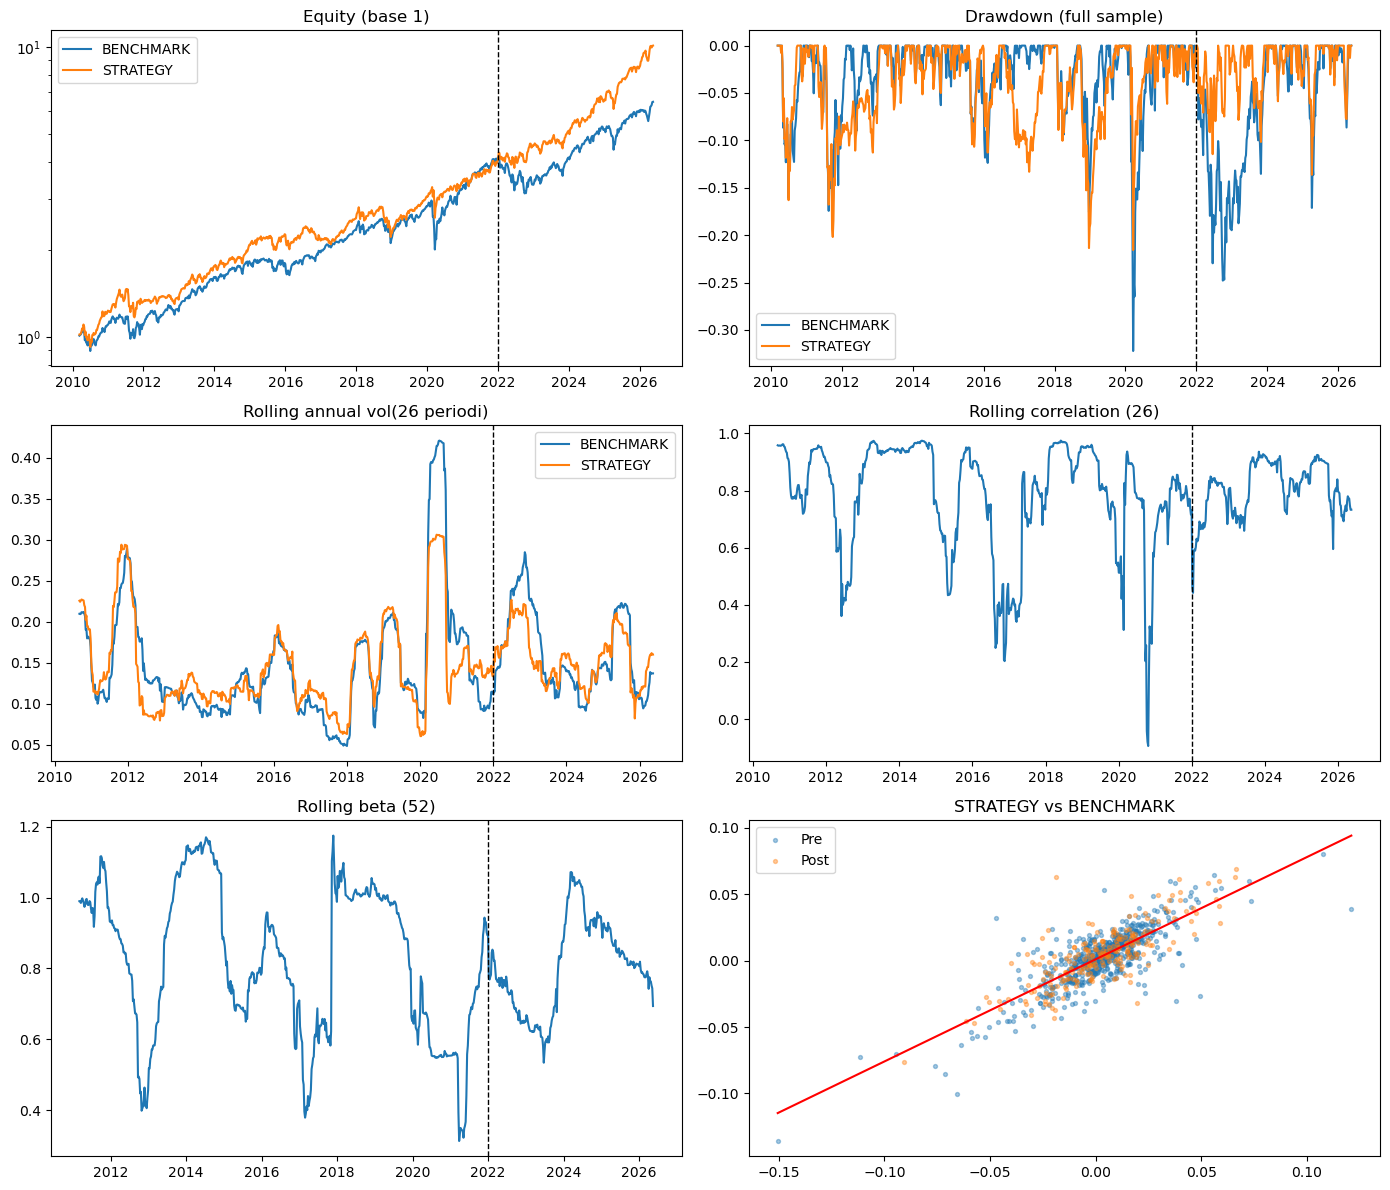

In [27]:
# ════════════════════════════════════════════════════════════════════
# APPENDIX A — STRATEGY vs BENCHMARK: full statistical test suite
# Pre / Post (OOS from 2022-01-01) + Full sample, weekly frequency.
# Copied from the original analysis; inputs wired to this notebook's variables.
# ════════════════════════════════════════════════════════════════════

import statsmodels.api as sm                         # CAPM / Treynor-Mazuy (HAC) regressions
from statsmodels.stats.diagnostic import acorr_ljungbox   # Ljung-Box on r and r^2
import scipy.stats as stats                          # Jarque-Bera, KS, Levene, skew/kurt

BENCHMARK = P["SPY"].dropna()      # SPY — OOS weekly returns (2010 → 2026)
STRATEGY  = s_target.dropna()      # baseline strategy: Equal(0.5) + ScoreWeighted — OOS gross

try:
    from IPython.display import display
except ImportError:
    display = print

# ---------------------------------------------------------------- parametri
PERIODS = 52       # 252 daily, 52 weekly (W-FRI), 12 monthly
ALPHA_Q = 0.10     # tail for VaR/ES (with weekly data 10% is more stable than 5%)
TAIL_Q = 0.10      # quantile for conditional correlation in the tails
ROLL = 26          # rolling window for vol/corr (26 weeks = 6 months)
ROLL_BETA = 52     # rolling window for beta (1 year)
HAC_LAGS = 4       # Newey-West lag
RF = 0.0           # risk-free rate per period (0 if you already return in excess)
SPLIT = "2022-01-01"   # first day of the "post" period (out-of-sample)


# ---------------------------------------------------------------- single series m,etrics
def drawdown_stats(r: pd.Series) -> dict:
    # The drawdown resets to zero at the start of each subperiod
    wealth = (1 + r).cumprod()
    dd = wealth / wealth.cummax() - 1
    under = dd < 0
    spells = under.groupby((~under).cumsum()).sum()   # Length of each underwater spell
    return {
        "Max drawdown": dd.min(),
        "Max time under water (periodi)": int(spells.max()),
        "% tempo under water": under.mean(),
    }


def tail_stats(r: pd.Series, q: float = ALPHA_Q) -> dict:
    thr = r.quantile(q)
    return {
        f"VaR {1-q:.0%} storico": -thr,
        f"ES {1-q:.0%} storico": -r[r <= thr].mean(),
    }


def dist_stats(r: pd.Series) -> dict:
    _, jb_p = stats.jarque_bera(r)
    lag = max(1, min(10, len(r) // 5))
    lb = acorr_ljungbox(r, lags=[lag], return_df=True)
    lb_sq = acorr_ljungbox(r**2, lags=[lag], return_df=True)
    return {
        "Skew": stats.skew(r),
        "Excess kurtosis": stats.kurtosis(r),
        "Jarque-Bera p": jb_p,
        "Autocorr lag 1": r.autocorr(1),
        "Ljung-Box p (r)": lb["lb_pvalue"].iloc[0],
        "Ljung-Box p (r^2) [ARCH]": lb_sq["lb_pvalue"].iloc[0],
    }


def perf_full(r: pd.Series) -> dict:
    n = len(r)
    ann_ret = (1 + r).prod() ** (PERIODS / n) - 1
    ann_vol = r.std() * np.sqrt(PERIODS)
    exc = r - RF
    sharpe = exc.mean() / r.std() * np.sqrt(PERIODS)
    dn = np.sqrt((np.minimum(exc, 0) ** 2).mean()) * np.sqrt(PERIODS)
    sortino = exc.mean() * PERIODS / dn
    return {
        "N observations": n,
        "Annual return (geom.)": ann_ret,
        "Annual Vol": ann_vol,
        "Vol drag (~sigma^2/2)": ann_vol**2 / 2,
        "Sharpe": sharpe,
        "Sortino": sortino,
    }


def full_report(r: pd.Series) -> pd.Series:
    d = {}
    for f in (perf_full, tail_stats, drawdown_stats, dist_stats):
        d.update(f(r))
    return pd.Series(d)


# ---------------------------------------------------------------- dipendenza
def tail_dependence(b: pd.Series, s: pd.Series, q: float = TAIL_Q) -> pd.Series:
    lo_b, hi_b = b.quantile(q), b.quantile(1 - q)
    lo_s = s.quantile(q)
    down, up = b <= lo_b, b >= hi_b
    return pd.Series({
        "Full Corr": b.corr(s),
        f"Corr | BENCH nel peggior {q:.0%}": b[down].corr(s[down]),
        f"Corr | BENCH nel miglior {q:.0%}": b[up].corr(s[up]),
        f"P(STRAT<q | BENCH<q) [atteso {q:.0%}]": (s[down] <= lo_s).mean(),
    })


# ---------------------------------------------------------------- regressione / alpha
def alpha_regression(b: pd.Series, s: pd.Series, lags: int = HAC_LAGS) -> dict:
    y, x = s - RF, b - RF
    out = {}
    X1 = pd.DataFrame({"const": 1.0, "bench": x})
    m = sm.OLS(y, X1).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    out["capm"] = m
    # Treynor-Mazuy: alpha net of convexity (market timing / optionality)
    X2 = pd.DataFrame({"const": 1.0, "bench": x, "bench2": x**2})
    out["tm"] = sm.OLS(y, X2).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    # Downside beta: only periods with BENCH < 0
    neg = x < 0
    out["down"] = sm.OLS(y[neg], X1[neg]).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

    a, beta = m.params["const"], m.params["bench"]
    out["summary"] = pd.Series({
        "Alpha annuo (aritmetic)": a * PERIODS,
        "Alpha t-stat (HAC)": m.tvalues["const"],
        "Alpha p-value": m.pvalues["const"],
        "Beta": beta,
        "Beta t-stat": m.tvalues["bench"],
        "R^2": m.rsquared,
        "Alpha annuo (Treynor-Mazuy)": out["tm"].params["const"] * PERIODS,
        "Convexity Coeff.' (bench^2)": out["tm"].params["bench2"],
        "Convexity t-stat": out["tm"].tvalues["bench2"],
        "Downside beta (BENCH<0)": out["down"].params["bench"],
        "Information ratio (alpha/TE)": a * PERIODS / (m.resid.std() * np.sqrt(PERIODS)),
        "STRAT return (annual mean)": y.mean() * PERIODS,
        "  of which beta * BENCH": beta * x.mean() * PERIODS,
        "  of which alpha": a * PERIODS,
    })
    return out


# ---------------------------------------------------------------- pre vs post
def split_series(b, s, split=SPLIT):
    cut = pd.Timestamp(split)
    return {
        "Pre": (b[b.index < cut], s[s.index < cut]),
        "Post": (b[b.index >= cut], s[s.index >= cut]),
        "Full": (b, s),
    }


def break_test(b: pd.Series, s: pd.Series, split=SPLIT, lags: int = HAC_LAGS) -> pd.DataFrame:
    """y = a + b*x + d_a*D + d_b*x*D ; D=1 dal split in poi. Test se alpha/beta cambiano."""
    x, y = b - RF, s - RF
    D = (x.index >= pd.Timestamp(split)).astype(float)
    X = pd.DataFrame({"const": 1.0, "bench": x, "D": D, "bD": x * D}, index=x.index)
    m = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    wald = m.wald_test("D = 0, bD = 0", scalar=True)
    rows = {
        "Delta alpha - annual (post - pre)": (m.params["D"] * PERIODS, m.pvalues["D"]),
        "Delta beta (post - pre)": (m.params["bD"], m.pvalues["bD"]),
        "Joint Test  fixed alpha & beta": (np.nan, float(wald.pvalue)),
    }
    return pd.DataFrame(rows, index=["stima", "p-value"]).T


def similarity_tests(parts: dict) -> pd.DataFrame:
    """Are the pre and post return distributions compatible? (KS on shape, Levene on variance)"""
    rows = {}
    for i, name in enumerate(("BENCH", "STRAT")):
        pre, post = parts["Pre"][i], parts["Post"][i]
        rows[name] = {
            "KS p (same disribution)": stats.ks_2samp(pre, post).pvalue,
            "Levene p (same variance)": stats.levene(pre, post).pvalue,
            "Annual Vol post/pre": post.std() / pre.std(),
        }
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- grafici
def plot_all(b, s, reg, split=SPLIT):
    fig, ax = plt.subplots(3, 2, figsize=(14, 12))
    ax = ax.ravel()
    cut = pd.Timestamp(split)

    for r, n in ((b, "BENCHMARK"), (s, "STRATEGY")):
        w = (1 + r).cumprod()
        ax[0].plot(w, label=n)
        ax[1].plot(w / w.cummax() - 1, label=n)
        ax[2].plot(r.rolling(ROLL).std() * np.sqrt(PERIODS), label=n)
    ax[0].set_title("Equity (base 1)"); ax[0].set_yscale("log")
    ax[1].set_title("Drawdown (full sample)")
    ax[2].set_title(f"Rolling annual vol({ROLL} periodi)")
    ax[3].plot(b.rolling(ROLL).corr(s))
    ax[3].set_title(f"Rolling correlation ({ROLL})")
    ax[4].plot(b.rolling(ROLL_BETA).cov(s) / b.rolling(ROLL_BETA).var())
    ax[4].set_title(f"Rolling beta ({ROLL_BETA})")

    pre, post = b.index < cut, b.index >= cut
    ax[5].scatter(b[pre], s[pre], s=8, alpha=0.4, label="Pre")
    ax[5].scatter(b[post], s[post], s=8, alpha=0.4, label="Post")
    xs = np.linspace(b.min(), b.max(), 100)
    p = reg["capm"].params
    ax[5].plot(xs, p["const"] + p["bench"] * xs, color="red")
    ax[5].set_title("STRATEGY vs BENCHMARK"); ax[5].legend()

    for a_ in ax[:5]:
        a_.axvline(cut, color="k", ls="--", lw=1)
    for a_ in ax[:3]:
        a_.legend()
    plt.tight_layout()
    return fig


# ---------------------------------------------------------------- main
def run(BENCHMARK: pd.Series, STRATEGY: pd.Series, split: str = SPLIT, show_plots: bool = True):
    df = pd.concat({"BENCHMARK": BENCHMARK, "STRATEGY": STRATEGY}, axis=1)
    n0 = len(df)
    df = df.dropna()
    print(f"Aligned observations: {len(df)} (dropped {n0 - len(df)} due to NaN/uncommon indexes)")
    b, s = df["BENCHMARK"], df["STRATEGY"]

    parts = split_series(b, s, split)
    for k, (bb, _) in parts.items():
        n_tail = int(len(bb) * ALPHA_Q)
        print(f"  {k:<5} N={len(bb):>4}  osservazioni in coda {ALPHA_Q:.0%}: {n_tail}"
              f"{'  <-- poche, ES not reliable' if n_tail < 20 else ''}")

    # 1) series metrics
    t1 = pd.concat({(p, n): full_report(x)
                    for p, (bb, ss) in parts.items()
                    for n, x in (("BENCH", bb), ("STRAT", ss))}, axis=1)
    t1 = t1[[c for c in [(p, n) for p in ("Pre", "Post", "Full") for n in ("BENCH", "STRAT")]]]
    print("\n=== TABLE 1: METRICS ===")
    display(t1.round(4))

    # 2)  STRAT vs BENCH
    regs = {p: alpha_regression(bb, ss) for p, (bb, ss) in parts.items()}
    t2 = pd.concat({p: pd.concat([tail_dependence(bb, ss), regs[p]["summary"]])
                    for p, (bb, ss) in parts.items()}, axis=1)[["Pre", "Post", "Full"]]
    print("\n=== TABLE 2: DEPENDANCE AND ALPHA (STRAT ~ BENCH, HAC) ===")
    display(t2.round(4))

    # 3) stability pre/post
    print("\n=== TABLE 3: DO ALPHA/BETA CHANGE AFTER THE SPLIT? ===")
    display(break_test(b, s, split).round(4))
    print("\n=== TABLE 4: DISTRIBUTION SIMILARITY PRE vs POST ===")
    display(similarity_tests(parts).round(4))

    if show_plots:
        plot_all(b, s, regs["Full"], split)
        plt.show()
    return t1, t2, regs

t1, t2, regs = run(BENCHMARK, STRATEGY)